# Predicting Graduate Earnings of U.S. Colleges
### End-to-end Machine Learning pipeline on the U.S. Department of Education *College Scorecard*

**Problem.** Students, families and regulators want to know what a college is "worth" in the labour market.
The College Scorecard publishes the median earnings of former students 10 years after they first enrolled
(`MD_EARN_WNE_P10`), but that number arrives a decade late and is missing or privacy-suppressed for about one
institution in six.

**Objective.** Build a supervised regression model that predicts an institution's 10-year median earnings from
characteristics that are observable much earlier: sector, programme mix, cost, student background, completion and
the local economy. A good model can (1) estimate earnings where the official figure is missing, (2) give an
"expected earnings" benchmark so that an institution can be compared against similar ones, and (3) show which
institutional characteristics travel with higher earnings.

**Unit of analysis.** One row = one institution (earnings are reported per 6-digit OPE ID).
**Target.** `MD_EARN_WNE_P10` in US dollars (continuous → regression; metrics: RMSE, MAE, MAPE, R²).

| Section | Content |
|---|---|
| 1 | Setup and data loading |
| 2 | Exploratory data analysis |
| 3 | Data preparation and feature engineering |
| 4 | Model training and hyperparameter tuning |
| 5 | Model evaluation |
| 6 | Export of models and artefacts |

## 1. Setup and Data Loading
### 1.1 Imports and configuration
All randomness is controlled by a single `RANDOM_STATE`, and every path is relative to the project folder, so the
notebook gives the same result on any machine.

In [ ]:
import json
import os
import platform
import sys
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from scipy import stats
from scipy.stats import loguniform, randint, uniform

from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import ElasticNet
from sklearn.metrics import (mean_absolute_error, mean_absolute_percentage_error,
                             median_absolute_error, r2_score, root_mean_squared_error)
from sklearn.model_selection import (GridSearchCV, KFold, RandomizedSearchCV,
                                     learning_curve, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (FunctionTransformer, OneHotEncoder, OrdinalEncoder,
                                   StandardScaler, TargetEncoder)
from sklearn.svm import SVR

# Custom transformer kept in an importable module so that saved pipelines can be re-loaded by the Streamlit app
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
from src.transformers import Winsorizer

warnings.filterwarnings("ignore", category=FutureWarning)

# NumPy 2.0 linked against Apple's Accelerate library (M-series Macs) emits spurious
# "divide by zero / overflow / invalid value encountered in matmul" warnings on perfectly finite inputs.
# The results are unaffected (Section 5.1 asserts that every prediction is finite), so only these three
# messages are silenced, here and in the parallel worker processes.
_MATMUL_MSGS = ["divide by zero encountered in matmul", "overflow encountered in matmul",
                "invalid value encountered in matmul"]
for _msg in _MATMUL_MSGS:
    warnings.filterwarnings("ignore", message=_msg, category=RuntimeWarning)
os.environ["PYTHONWARNINGS"] = ",".join(f"ignore:{m}:RuntimeWarning" for m in _MATMUL_MSGS)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

DATA_RAW = ROOT / "data" / "Most-Recent-Cohorts-Institution.csv"
DATA_PROCESSED = ROOT / "data" / "processed"
MODELS_DIR = ROOT / "models"
REPORTS_DIR = ROOT / "reports"
FIG_DIR = REPORTS_DIR / "figures"
for folder in (DATA_PROCESSED, MODELS_DIR, REPORTS_DIR, FIG_DIR):
    folder.mkdir(parents=True, exist_ok=True)

TARGET = "MD_EARN_WNE_P10"

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
                     "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

CONTROL_PALETTE = {"Public": "#2a78d6", "Private nonprofit": "#1baf7a", "Private for-profit": "#eb7a2d"}


def save_fig(name):
    """Save the current figure to reports/figures (used later by the report and the app)."""
    plt.savefig(FIG_DIR / f"{name}.png")


print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"scikit-learn {sklearn.__version__}")

Python 3.9.6 | pandas 2.3.3 | numpy 2.0.2 | scikit-learn 1.6.1


### 1.2 Load the dataset
The file is the *Most Recent Cohorts – Institution* table of the College Scorecard
(<https://collegescorecard.ed.gov/data/>, U.S. Department of Education, public domain).
It is itself a **multi-source join** made by the Department: IPEDS survey data (institution characteristics, cost,
enrolment), NSLDS (federal student-aid records) and Treasury tax records (earnings), linked by `UNITID` / `OPEID6`.
No further join is needed.

The table has 3,379 columns. Most are fine-grained breakdowns that are irrelevant or almost entirely empty, so only
the columns needed for the problem are read. They are grouped by meaning below.

In [ ]:
COLUMN_GROUPS = {
    "identifiers": ["UNITID", "OPEID6", "INSTNM", "CITY", "STABBR", "LATITUDE", "LONGITUDE"],
    "structure": ["MAIN", "NUMBRANCH", "PREDDEG", "HIGHDEG", "CONTROL", "REGION", "LOCALE", "CURROPER",
                  "HBCU", "MENONLY", "WOMENONLY", "DISTANCEONLY", "OPENADMP"],
    "admissions": ["ADM_RATE", "SAT_AVG"],
    "student_body": ["UGDS", "UGDS_WHITE", "UGDS_BLACK", "UGDS_HISP", "UGDS_ASIAN", "UGDS_AIAN", "UGDS_NHPI",
                     "UGDS_2MOR", "UGDS_NRA", "UGDS_UNKN", "UGDS_MEN", "UGDS_WOMEN", "PPTUG_EF", "UG25ABV",
                     "PCTPELL", "PCTFLOAN"],
    "cost_and_finance": ["TUITIONFEE_IN", "TUITIONFEE_OUT", "TUITIONFEE_PROG", "COSTT4_A", "COSTT4_P",
                         "NPT4_PUB", "NPT4_PRIV", "TUITFTE", "INEXPFTE", "AVGFACSAL", "PFTFAC", "STUFACR"],
    "academic_progress": ["C150_4", "C150_L4", "RET_FT4", "RET_FTL4"],
    "student_background": ["MD_FAMINC", "FIRST_GEN", "AGE_ENTRY", "DEPENDENT", "MARRIED",
                           "MEDIAN_HH_INC", "POVERTY_RATE", "UNEMP_RATE", "PCT_BA"],
    "target_and_related": [TARGET, "COUNT_WNE_P10", "MD_EARN_WNE_P6"],
}

header = pd.read_csv(DATA_RAW, nrows=0).columns
PCIP_COLS = [c for c in header if c.startswith("PCIP")]          # share of awards per field of study
COLUMN_GROUPS["programme_mix"] = PCIP_COLS
USE_COLS = [c for group in COLUMN_GROUPS.values() for c in group]
assert set(USE_COLS) <= set(header), "A requested column is not in the file"

raw = pd.read_csv(DATA_RAW, usecols=USE_COLS, low_memory=False)[USE_COLS]
raw["OPEID6"] = raw["OPEID6"].astype("Int64")        # an identifier, not a quantity

print(f"Full file      : {len(raw):,} rows x {len(header):,} columns")
print(f"Loaded subset  : {raw.shape[0]:,} rows x {raw.shape[1]} columns "
      f"({raw.memory_usage(deep=True).sum() / 1e6:.1f} MB in memory)")
raw.head()

Full file      : 6,272 rows x 3,379 columns
Loaded subset  : 6,272 rows x 104 columns (10.5 MB in memory)


,UNITID,OPEID6,INSTNM,CITY,STABBR,LATITUDE,LONGITUDE,MAIN,NUMBRANCH,PREDDEG,HIGHDEG,CONTROL,REGION,LOCALE,CURROPER,HBCU,MENONLY,WOMENONLY,DISTANCEONLY,OPENADMP,ADM_RATE,SAT_AVG,UGDS,UGDS_WHITE,UGDS_BLACK,UGDS_HISP,UGDS_ASIAN,UGDS_AIAN,UGDS_NHPI,UGDS_2MOR,...,PCIP13,PCIP14,PCIP15,PCIP16,PCIP19,PCIP22,PCIP23,PCIP24,PCIP25,PCIP26,PCIP27,PCIP29,PCIP30,PCIP31,PCIP38,PCIP39,PCIP40,PCIP41,PCIP42,PCIP43,PCIP44,PCIP45,PCIP46,PCIP47,PCIP48,PCIP49,PCIP50,PCIP51,PCIP52,PCIP54
0,100654,1002,Alabama A & M University,Normal,AL,34.783,-86.569,1,1,3,4,1,5,12.000,1,1.000,0.000,0.000,0.000,2.000,0.580,938.000,"6,124.000",0.016,0.901,0.021,0.002,0.001,0.001,0.022,...,0.049,0.116,0.036,0.000,0.029,0.000,0.011,0.088,0.000,0.105,0.008,0.000,0.000,0.041,0.000,0.000,0.005,0.000,0.056,0.067,0.026,0.023,0.000,0.000,0.000,0.000,0.011,0.000,0.169,0.000
1,100663,1052,University of Alabama at Birmingham,Birmingham,AL,33.506,-86.799,1,1,3,4,1,5,12.000,1,0.000,0.000,0.000,0.000,2.000,0.882,"1,258.000","11,635.000",0.465,0.271,0.086,0.094,0.001,0.001,0.052,...,0.055,0.065,0.000,0.009,0.000,0.000,0.013,0.027,0.000,0.145,0.004,0.000,0.004,0.000,0.004,0.000,0.014,0.000,0.092,0.034,0.010,0.022,0.000,0.000,0.000,0.000,0.022,0.193,0.213,0.009
2,100690,25034,Amridge University,Montgomery,AL,32.363,-86.174,1,1,3,4,2,5,12.000,1,0.000,0.000,0.000,1.000,1.000,NaN,NaN,241.000,0.257,0.697,0.021,0.004,0.000,0.000,0.000,...,0.000,0.000,0.000,0.000,0.154,0.000,0.000,0.015,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.277,0.000,0.000,0.000,0.108,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.446,0.000
3,100706,1055,University of Alabama in Huntsville,Huntsville,AL,34.725,-86.640,1,1,3,4,1,5,12.000,1,0.000,0.000,0.000,0.000,2.000,0.686,"1,319.000","6,591.000",0.678,0.094,0.080,0.043,0.006,0.001,0.052,...,0.011,0.287,0.009,0.008,0.003,0.000,0.016,0.000,0.000,0.051,0.018,0.000,0.020,0.026,0.001,0.000,0.040,0.000,0.023,0.000,0.000,0.027,0.000,0.000,0.000,0.000,0.045,0.097,0.205,0.012
4,100724,1005,Alabama State University,Montgomery,AL,32.364,-86.296,1,1,3,4,1,5,12.000,1,1.000,0.000,0.000,0.000,2.000,0.976,976.000,"3,477.000",0.018,0.863,0.014,0.002,0.001,0.000,0.012,...,0.079,0.027,0.000,0.000,0.000,0.000,0.002,0.000,0.000,0.129,0.010,0.000,0.104,0.008,0.000,0.000,0.015,0.000,0.079,0.112,0.035,0.035,0.000,0.000,0.000,0.000,0.100,0.058,0.100,0.004


## 2. Exploratory Data Analysis
### 2.1 Shape, data types and structural errors
The first look is at the *raw* table, before any fix, to find problems with its structure.

In [ ]:
print("Shape:", raw.shape)
print("\nData types as read from the file:")
print(raw.dtypes.value_counts().to_string())

print("\nDuplicated rows     :", raw.duplicated().sum())
print("Duplicated UNITID   :", raw["UNITID"].duplicated().sum())
print("Institutions sharing an OPEID6 with another row:", raw["OPEID6"].duplicated(keep=False).sum())

Shape: (6272, 104)

Data types as read from the file:
float64    80
object     15
int64       8
Int64       1

Duplicated rows     : 0
Duplicated UNITID   : 0
Institutions sharing an OPEID6 with another row: 1782


Many columns that should be numeric were read as text (`object`). The cell below finds out why.

In [ ]:
ID_TEXT_COLS = ["INSTNM", "CITY", "STABBR"]
object_cols = [c for c in raw.columns if raw[c].dtype == "object" and c not in ID_TEXT_COLS]

# Every value in those columns that cannot be parsed as a number
non_numeric = {}
for c in object_cols:
    bad = raw.loc[pd.to_numeric(raw[c], errors="coerce").isna() & raw[c].notna(), c]
    non_numeric[c] = bad.value_counts().to_dict()

tokens = pd.DataFrame(non_numeric).T.fillna(0).astype(int)
print(f"{len(object_cols)} numeric columns were read as text. Non-numeric tokens found:")
tokens.sort_values(tokens.columns[0], ascending=False)

12 numeric columns were read as text. Non-numeric tokens found:


,PS
MARRIED,851
FIRST_GEN,685
MD_EARN_WNE_P10,622
COUNT_WNE_P10,622
MD_EARN_WNE_P6,501
DEPENDENT,439
PCT_BA,118
MD_FAMINC,109
AGE_ENTRY,109
MEDIAN_HH_INC,85


**Finding – structural error.** The only non-numeric token is **`PS`** ("Privacy Suppressed"): the Department hides
a value when it is based on too few students. It is not a number and not a category; it is a *missing value with a
known reason*. It is converted to `NaN` so the columns become numeric. The suppression is not random (it hits small
institutions), which matters later when missing values are imputed.

In [ ]:
df = raw.copy()
n_ps_cells = int((df[object_cols] == "PS").sum().sum())
df[object_cols] = df[object_cols].apply(pd.to_numeric, errors="coerce")   # 'PS' -> NaN

print(f"{n_ps_cells:,} privacy-suppressed cells converted to NaN.")
print("\nData types after the fix:")
print(df.dtypes.value_counts().to_string())
df.info(verbose=False, memory_usage="deep")

4,311 privacy-suppressed cells converted to NaN.

Data types after the fix:
float64    92
int64       8
object      3
Int64       1
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6272 entries, 0 to 6271
Columns: 104 entries, UNITID to PCIP54
dtypes: Int64(1), float64(92), int64(8), object(3)
memory usage: 6.1 MB


### 2.2 Missing values

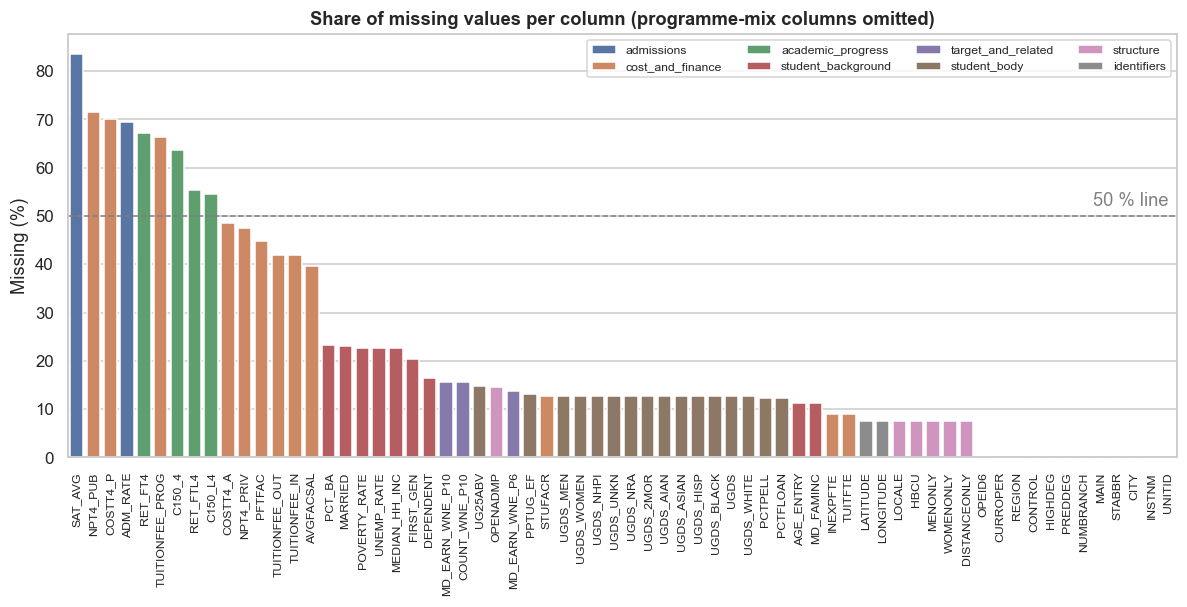

Target 'MD_EARN_WNE_P10' is missing for 15.7% of institutions (983 rows).
Programme-mix (PCIP) columns: 11.7 % missing on average.


In [ ]:
missing = (df.isna().mean() * 100).sort_values(ascending=False)
group_of = {c: g for g, cols in COLUMN_GROUPS.items() for c in cols}
missing_tbl = pd.DataFrame({"missing_%": missing.round(1), "group": missing.index.map(group_of)})

non_pcip = missing_tbl[missing_tbl["group"] != "programme_mix"]
fig, ax = plt.subplots(figsize=(13, 5))
sns.barplot(x=non_pcip.index, y=non_pcip["missing_%"], hue=non_pcip["group"], dodge=False, ax=ax)
ax.axhline(50, ls="--", c="grey", lw=1)
ax.text(len(non_pcip) - 1, 52, "50 % line", ha="right", color="grey")
ax.set(title="Share of missing values per column (programme-mix columns omitted)", xlabel="", ylabel="Missing (%)")
ax.tick_params(axis="x", rotation=90, labelsize=8)
ax.legend(title="", fontsize=8, ncol=4, loc="upper right")
save_fig("eda_missing_values"); plt.show()

print(f"Target '{TARGET}' is missing for {df[TARGET].isna().mean():.1%} of institutions "
      f"({df[TARGET].isna().sum():,} rows).")
print(f"Programme-mix (PCIP) columns: {missing_tbl.loc[PCIP_COLS, 'missing_%'].mean():.1f} % missing on average.")

**Finding – missingness has structure.** The columns come in complementary pairs: `NPT4_PUB` is filled only for
public colleges and `NPT4_PRIV` only for private ones; `C150_4` / `RET_FT4` only for 4-year colleges and
`C150_L4` / `RET_FTL4` only for shorter ones; `COSTT4_A` only for academic-year colleges and `COSTT4_P` only for
programme-year ones. These are not really missing: each pair is one variable split in two. Section 3 merges them
back. `SAT_AVG` and `ADM_RATE` are missing mostly because open-admission colleges do not collect them.

In [ ]:
pairs = [("NPT4_PUB", "NPT4_PRIV"), ("C150_4", "C150_L4"), ("RET_FT4", "RET_FTL4"), ("COSTT4_A", "COSTT4_P")]
pd.DataFrame([{"pair": f"{a} / {b}",
               "only first": int((df[a].notna() & df[b].isna()).sum()),
               "only second": int((df[a].isna() & df[b].notna()).sum()),
               "both": int((df[a].notna() & df[b].notna()).sum()),
               "neither": int((df[a].isna() & df[b].isna()).sum())} for a, b in pairs]).set_index("pair")

,only first,only second,both,neither
pair,,,,
NPT4_PUB / NPT4_PRIV,1781,3294,0,1197
C150_4 / C150_L4,2278,2854,0,1140
RET_FT4 / RET_FTL4,2057,2804,0,1411
COSTT4_A / COSTT4_P,3228,1874,0,1170


### 2.3 Summary statistics: central tendency and spread
Mean and median show the centre; variance, standard deviation and IQR show the spread; skewness and kurtosis show
the shape. A mean far above the median, or a large skewness, signals a long right tail, which is where outliers
live and where a log transform helps.

In [ ]:
KEY_NUMERIC = [TARGET, "UGDS", "TUITIONFEE_IN", "COSTT4_A", "INEXPFTE", "TUITFTE", "AVGFACSAL", "STUFACR",
               "PCTPELL", "PCTFLOAN", "ADM_RATE", "SAT_AVG", "C150_4", "C150_L4", "MD_FAMINC", "FIRST_GEN",
               "AGE_ENTRY", "MEDIAN_HH_INC", "POVERTY_RATE", "UNEMP_RATE"]

desc = df[KEY_NUMERIC].describe().T
summary = pd.DataFrame({
    "count": desc["count"].astype(int),
    "mean": desc["mean"],
    "median": desc["50%"],
    "mode": df[KEY_NUMERIC].mode().iloc[0],
    "variance": df[KEY_NUMERIC].var(),
    "std": desc["std"],
    "min": desc["min"],
    "max": desc["max"],
    "IQR": desc["75%"] - desc["25%"],
    "skewness": df[KEY_NUMERIC].skew(),
    "kurtosis": df[KEY_NUMERIC].kurt(),
})
summary.to_csv(REPORTS_DIR / "eda_summary_statistics.csv")
summary

,count,mean,median,mode,variance,std,min,max,IQR,skewness,kurtosis
MD_EARN_WNE_P10,5289,"48,641.255","45,574.000","30,056.000","312,378,989.175","17,674.246","14,374.000","166,642.000","21,174.000",1.225,2.710
UGDS,5477,"2,641.610",564.000,31.000,"42,606,681.310","6,527.379",0.000,"163,164.000","2,093.000",8.525,141.806
TUITIONFEE_IN,3645,"18,248.558","12,115.000","13,920.000","289,527,947.860","17,015.521",0.000,"76,040.000","18,402.000",1.451,1.387
COSTT4_A,3228,"32,703.690","26,718.000","28,444.000","398,100,760.569","19,952.463","3,976.000","95,168.000","26,250.000",1.165,0.688
INEXPFTE,5706,"10,066.806","7,261.500",0.000,"231,302,659.057","15,208.638",0.000,"695,895.000","6,883.750",19.948,762.859
TUITFTE,5706,"11,874.631","10,449.000",0.000,"104,406,891.273","10,217.969",0.000,"236,267.000","10,074.000",5.102,75.328
AVGFACSAL,3780,"8,048.055","7,618.000","8,381.000","8,767,316.853","2,960.966",729.000,"25,354.000","3,362.500",1.043,2.785
STUFACR,5470,15.796,15.000,15.000,64.137,8.009,1.000,191.000,9.000,3.971,59.437
PCTPELL,5498,0.453,0.433,0.000,0.046,0.214,0.000,1.000,0.305,0.280,-0.395
PCTFLOAN,5498,0.399,0.419,0.000,0.076,0.276,0.000,1.000,0.487,0.039,-1.139


**Findings.**
* **Target:** the mean is above the median and skewness is clearly positive, so earnings have a right tail.
* **Size and money columns** (`UGDS`, `INEXPFTE`, `TUITFTE`) are extremely skewed, with maxima tens of times the
  median. These need a log transform and outlier capping.
* **Impossible minima:** `UGDS`, `INEXPFTE`, `TUITFTE`, `ADM_RATE` and the completion rates have a minimum of
  exactly 0. A college that is operating cannot have zero students, spend nothing on teaching or admit nobody.
  These are data errors and are treated in Section 3.

### 2.4 The target variable
From here on, EDA uses the rows that have a target value, with readable labels for the main categories.

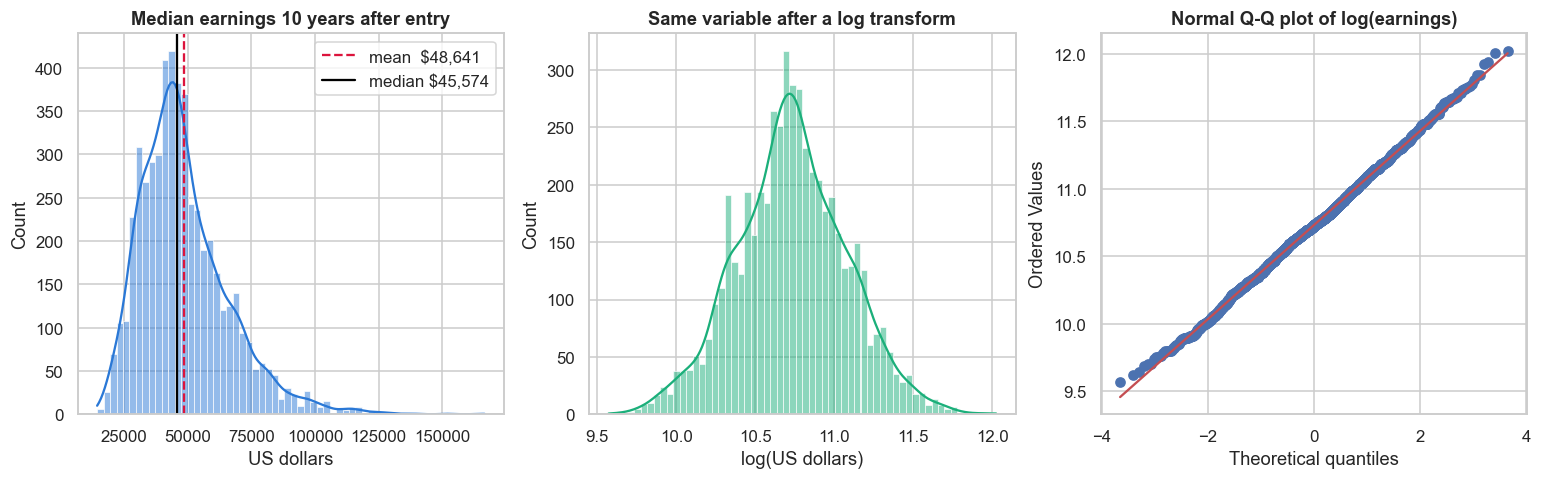

Skewness  raw: 1.22   log: 0.05
Kurtosis  raw: 2.71   log: 0.07
IQR rule (1.5 x IQR): 159 institutions (3.0%) flagged as outliers, all above $89,369.


,INSTNM,STABBR,Control,Predominant degree,MD_EARN_WNE_P10
183,California Institute of Technology,CA,Private nonprofit,Bachelor,"166,642.000"
287,Harvey Mudd College,CA,Private nonprofit,Bachelor,"164,248.000"
1383,Massachusetts Institute of Technology,MA,Private nonprofit,Bachelor,"152,553.000"
393,Samuel Merritt University,CA,Private nonprofit,Bachelor,"151,150.000"
1330,Babson College,MA,Private nonprofit,Bachelor,"138,950.000"
4154,Franklin W Olin College of Engineering,MA,Private nonprofit,Bachelor,"138,832.000"
1864,Princeton University,NJ,Private nonprofit,Bachelor,"133,523.000"
1705,University of Health Sciences and Pharmacy in ...,MO,Private nonprofit,Bachelor,"130,161.000"


In [ ]:
CONTROL_MAP = {1: "Public", 2: "Private nonprofit", 3: "Private for-profit"}
PREDDEG_MAP = {0: "Not classified", 1: "Certificate", 2: "Associate", 3: "Bachelor", 4: "Graduate"}
REGION_MAP = {0: "U.S. Service Schools", 1: "New England", 2: "Mid East", 3: "Great Lakes", 4: "Plains",
              5: "Southeast", 6: "Southwest", 7: "Rocky Mountains", 8: "Far West", 9: "Outlying Areas"}

eda = df[df[TARGET].notna()].copy()
eda["Control"] = eda["CONTROL"].map(CONTROL_MAP)
eda["Predominant degree"] = eda["PREDDEG"].map(PREDDEG_MAP)
eda["Region"] = eda["REGION"].map(REGION_MAP)
y_all = eda[TARGET]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.histplot(y_all, bins=60, kde=True, ax=axes[0], color="#2a78d6")
axes[0].axvline(y_all.mean(), c="crimson", ls="--", label=f"mean  ${y_all.mean():,.0f}")
axes[0].axvline(y_all.median(), c="black", ls="-", label=f"median ${y_all.median():,.0f}")
axes[0].set(title="Median earnings 10 years after entry", xlabel="US dollars"); axes[0].legend()

sns.histplot(np.log(y_all), bins=60, kde=True, ax=axes[1], color="#1baf7a")
axes[1].set(title="Same variable after a log transform", xlabel="log(US dollars)")

stats.probplot(np.log(y_all), dist="norm", plot=axes[2])
axes[2].set_title("Normal Q-Q plot of log(earnings)")
save_fig("eda_target_distribution"); plt.show()

q1, q3 = y_all.quantile([0.25, 0.75]); iqr = q3 - q1
n_out = int(((y_all < q1 - 1.5 * iqr) | (y_all > q3 + 1.5 * iqr)).sum())
print(f"Skewness  raw: {stats.skew(y_all):.2f}   log: {stats.skew(np.log(y_all)):.2f}")
print(f"Kurtosis  raw: {stats.kurtosis(y_all):.2f}   log: {stats.kurtosis(np.log(y_all)):.2f}")
print(f"IQR rule (1.5 x IQR): {n_out} institutions ({n_out / len(y_all):.1%}) flagged as outliers, "
      f"all above ${q3 + 1.5 * iqr:,.0f}." if (y_all < q1 - 1.5 * iqr).sum() == 0 else
      f"IQR rule (1.5 x IQR): {n_out} institutions ({n_out / len(y_all):.1%}) flagged as outliers.")
eda.nlargest(8, TARGET)[["INSTNM", "STABBR", "Control", "Predominant degree", TARGET]]

**Findings.** Raw earnings are right-skewed; the log removes almost all of the skew and the Q-Q plot is close to a
straight line. The models are therefore trained on **log(earnings)** and their predictions are converted back to
dollars. The highest earners are real institutions (health-science, pharmacy, maritime and engineering schools),
not errors, so they are **kept**: deleting them would remove exactly the cases the model must be able to predict.

### 2.5 Earnings by type of institution (box plots)
Box plots compare the centre, spread and outliers of earnings across groups in one picture.

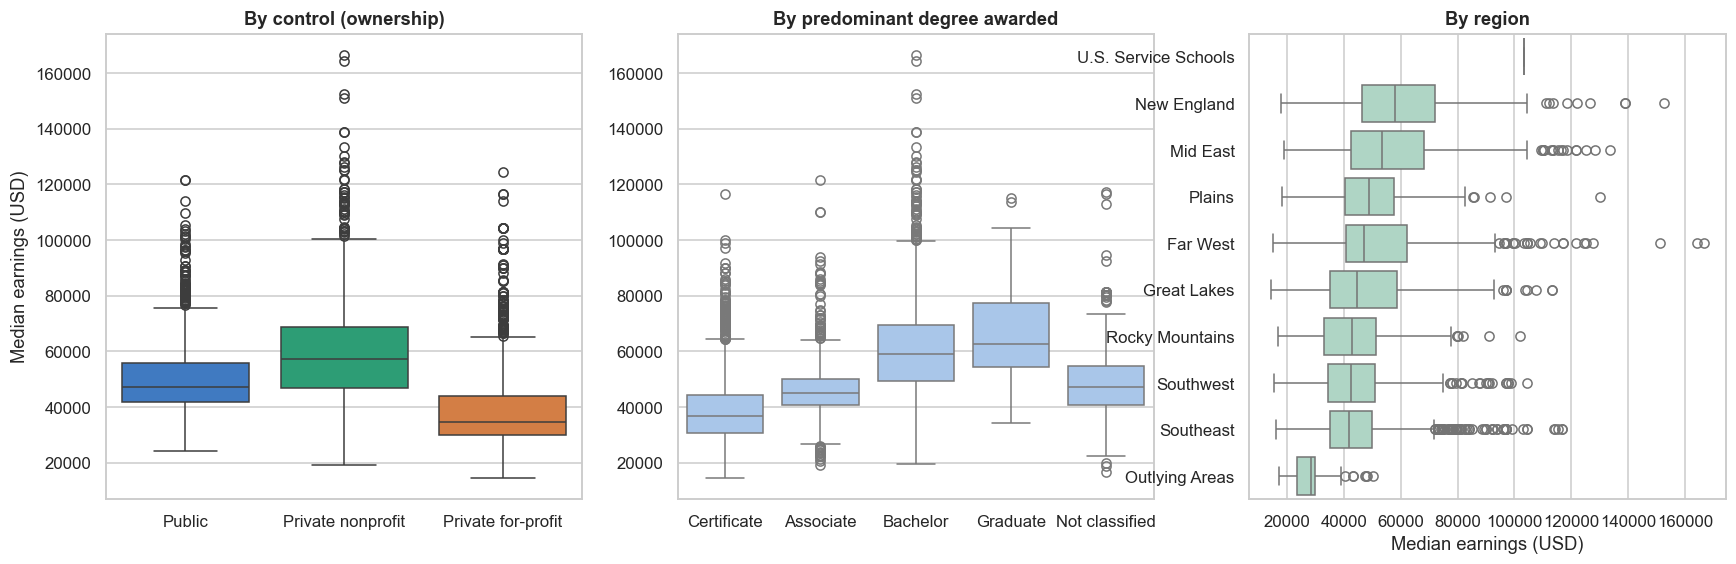

Kruskal-Wallis test, earnings by control: H = 1,482.2, p = 0.00e+00


,count,median,mean,std
Control,,,,
Private for-profit,1856,"34,706.000","38,625.000","14,887.000"
Private nonprofit,1453,"57,332.000","59,298.000","19,627.000"
Public,1980,"47,011.000","50,210.000","12,822.000"


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
sns.boxplot(data=eda, x="Control", y=TARGET, hue="Control", palette=CONTROL_PALETTE,
            order=list(CONTROL_PALETTE), legend=False, ax=axes[0])
axes[0].set(title="By control (ownership)", xlabel="", ylabel="Median earnings (USD)")

deg_order = ["Certificate", "Associate", "Bachelor", "Graduate", "Not classified"]
sns.boxplot(data=eda, x="Predominant degree", y=TARGET, order=deg_order, color="#9ec5f4", ax=axes[1])
axes[1].set(title="By predominant degree awarded", xlabel="", ylabel="")

reg_order = eda.groupby("Region")[TARGET].median().sort_values(ascending=False).index
sns.boxplot(data=eda, y="Region", x=TARGET, order=reg_order, color="#a8dcc6", ax=axes[2])
axes[2].set(title="By region", xlabel="Median earnings (USD)", ylabel="")
save_fig("eda_boxplots_by_group"); plt.show()

groups = [g[TARGET].values for _, g in eda.groupby("Control")]
h, p = stats.kruskal(*groups)
print(f"Kruskal-Wallis test, earnings by control: H = {h:,.1f}, p = {p:.2e}")
eda.groupby("Control")[TARGET].agg(["count", "median", "mean", "std"]).round(0)

**Findings.** Private for-profit colleges sit far below the other two sectors, and earnings rise with the level of
the predominant degree (certificate < associate < bachelor). The Kruskal-Wallis test (used instead of ANOVA because
the groups are skewed and have unequal variance) confirms the sector differences are not due to chance. "Outlying
Areas" (Puerto Rico and other territories) are an anomaly at the low end, reflecting a different labour market.
`CONTROL`, `PREDDEG` and geography must be model features.

### 2.6 Relationships with numeric features (scatter plots)

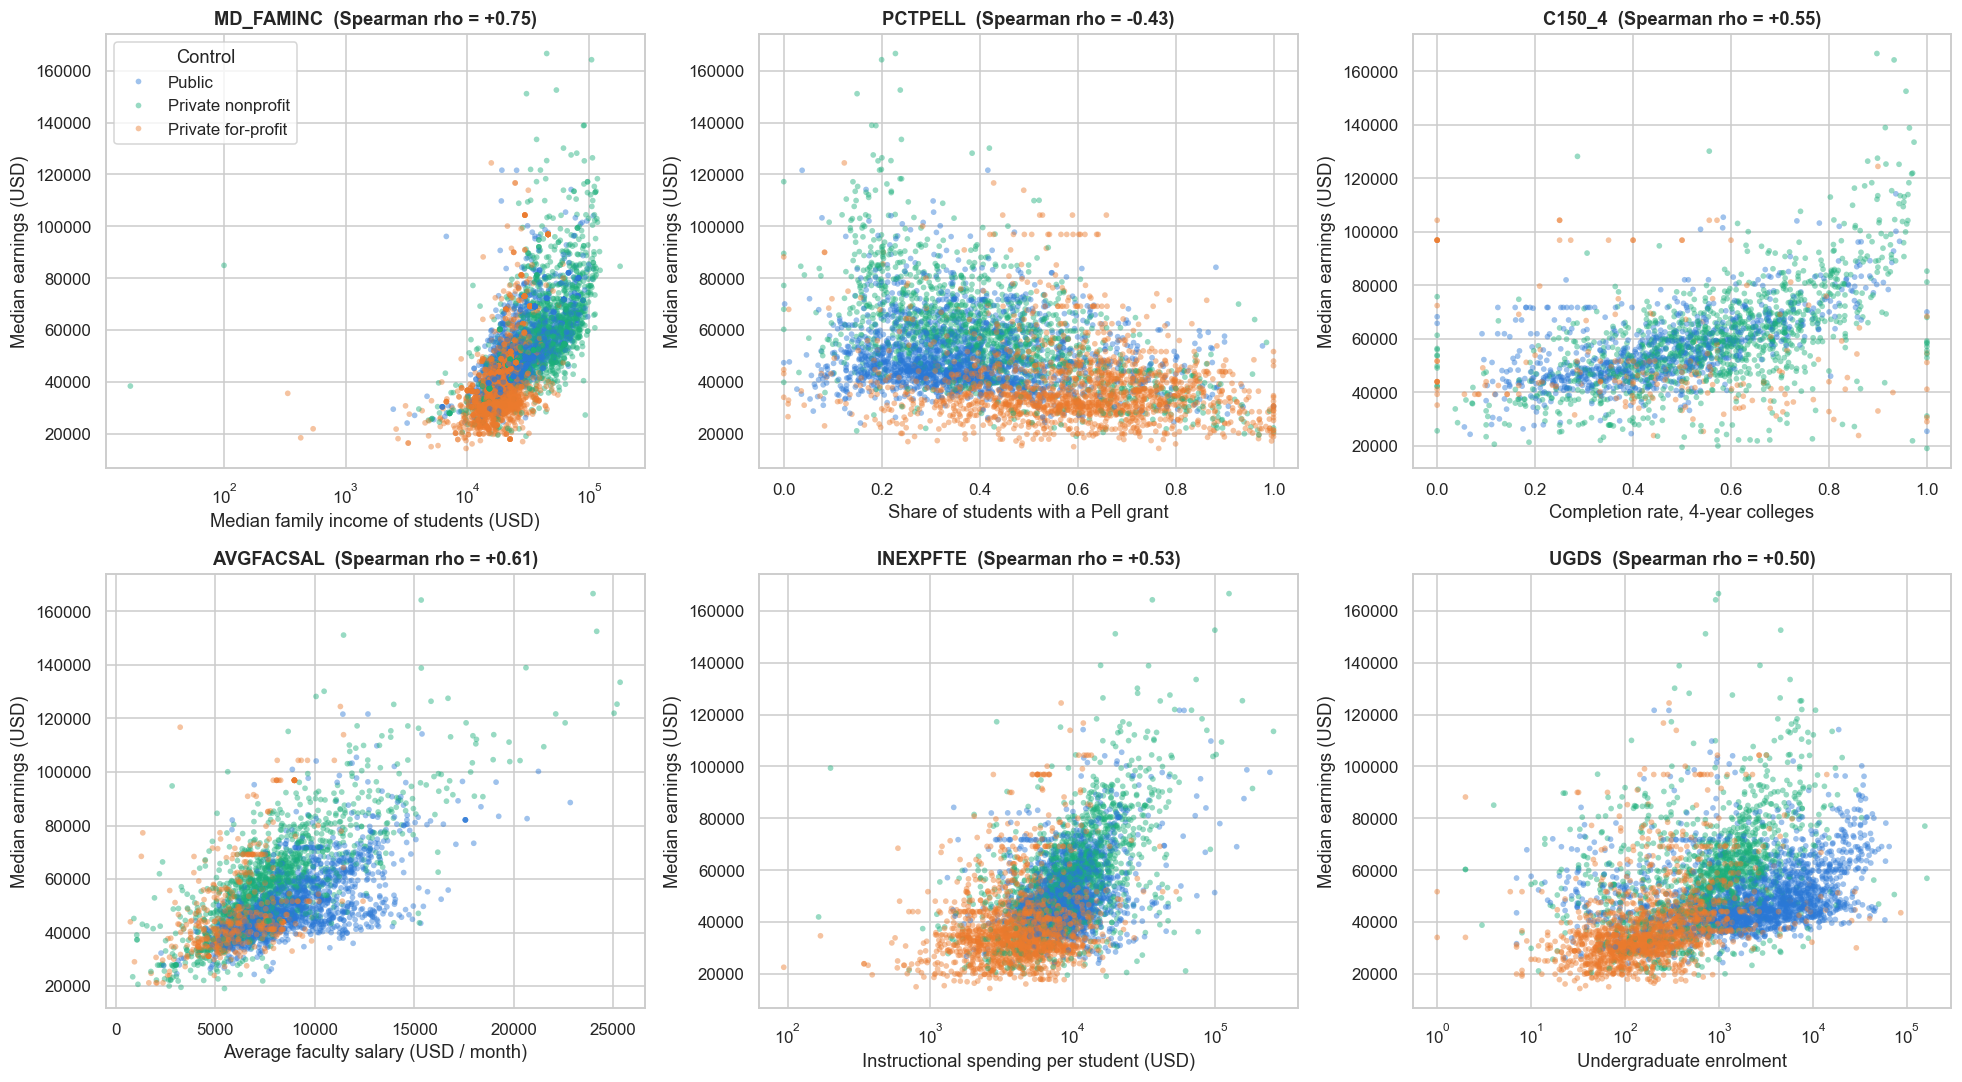

In [ ]:
scatter_vars = [("MD_FAMINC", "Median family income of students (USD)", True),
                ("PCTPELL", "Share of students with a Pell grant", False),
                ("C150_4", "Completion rate, 4-year colleges", False),
                ("AVGFACSAL", "Average faculty salary (USD / month)", False),
                ("INEXPFTE", "Instructional spending per student (USD)", True),
                ("UGDS", "Undergraduate enrolment", True)]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, (col, label, logx) in zip(axes.ravel(), scatter_vars):
    data = eda[eda[col] > 0] if logx else eda
    sns.scatterplot(data=data, x=col, y=TARGET, hue="Control", palette=CONTROL_PALETTE,
                    hue_order=list(CONTROL_PALETTE), s=14, alpha=0.45, linewidth=0, ax=ax, legend="auto" if ax is axes[0, 0] else False)
    rho, _ = stats.spearmanr(data[col], data[TARGET], nan_policy="omit")
    if logx:
        ax.set_xscale("log")
    ax.set(title=f"{col}  (Spearman rho = {rho:+.2f})", xlabel=label, ylabel="Median earnings (USD)")
plt.tight_layout(); save_fig("eda_scatter_plots"); plt.show()

**Findings.** Earnings rise with the family income of the students a college enrols, with completion and with
faculty salary, and fall as the share of low-income (Pell) students grows. The relationships are monotonic but
**curved** and they differ by sector, which suggests that models able to capture non-linearity and interactions
(trees, kernels) should beat a purely linear model. The size and spending axes need a log scale to be readable at
all, which confirms the need for a log transform of those features.

### 2.7 Feature distributions (histograms)

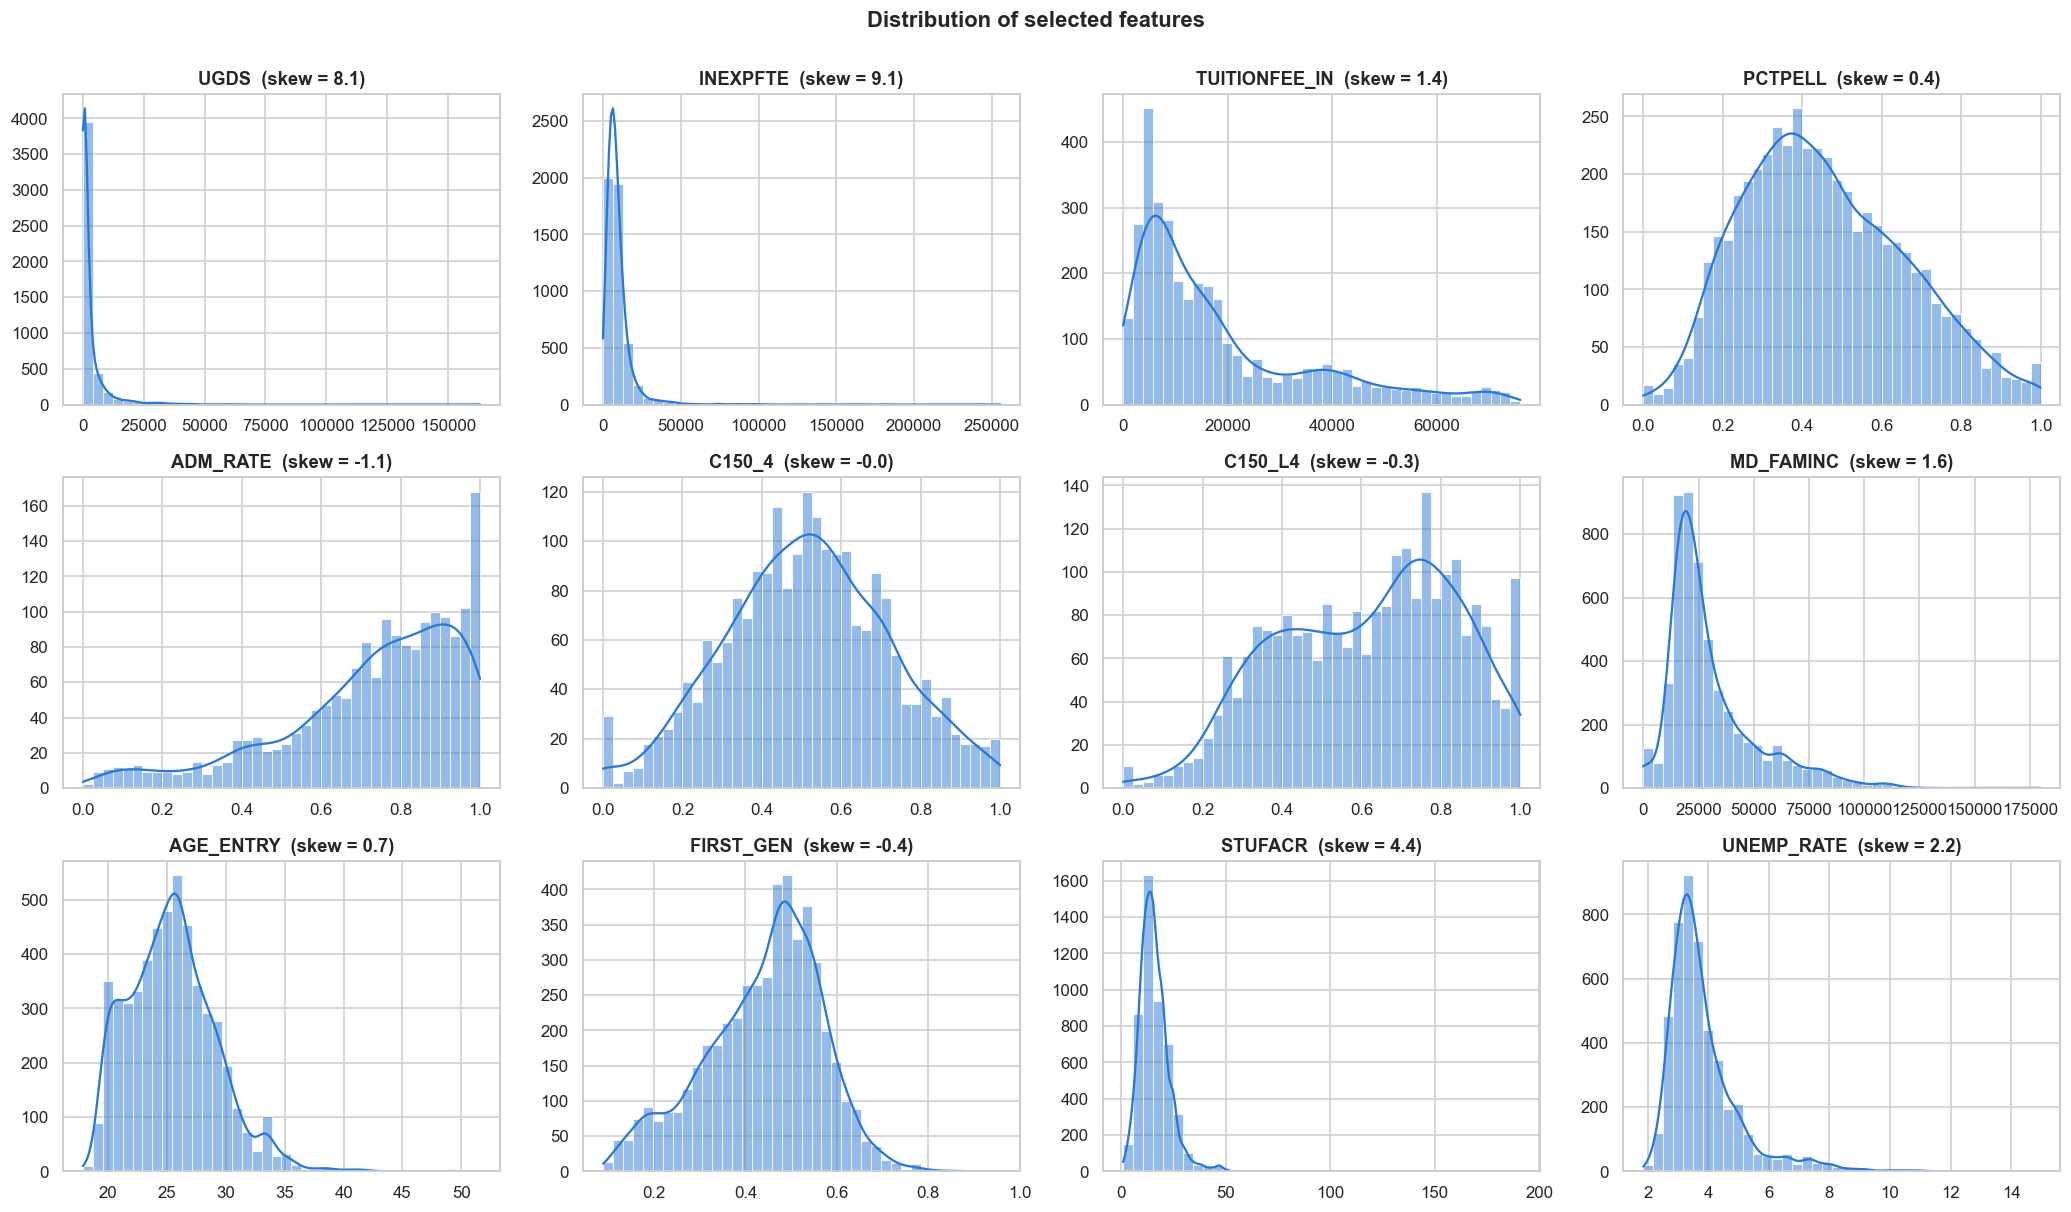

In [ ]:
hist_vars = ["UGDS", "INEXPFTE", "TUITIONFEE_IN", "PCTPELL", "ADM_RATE", "C150_4",
             "C150_L4", "MD_FAMINC", "AGE_ENTRY", "FIRST_GEN", "STUFACR", "UNEMP_RATE"]
fig, axes = plt.subplots(3, 4, figsize=(19, 11))
for ax, col in zip(axes.ravel(), hist_vars):
    sns.histplot(eda[col].dropna(), bins=40, kde=True, ax=ax, color="#2a78d6")
    ax.set(title=f"{col}  (skew = {eda[col].skew():.1f})", xlabel="", ylabel="")
plt.suptitle("Distribution of selected features", y=1.0, fontweight="bold")
plt.tight_layout(); save_fig("eda_feature_histograms"); plt.show()

**Findings.** `UGDS` and `INEXPFTE` are so skewed that the histogram is a single bar next to zero, with a few huge
values stretching the axis. `AGE_ENTRY` is bimodal: colleges serving school-leavers (about 20) and colleges serving
working adults (about 28). `ADM_RATE` piles up at 1.0 and `STUFACR` has implausible extreme values.

### 2.8 Programme mix

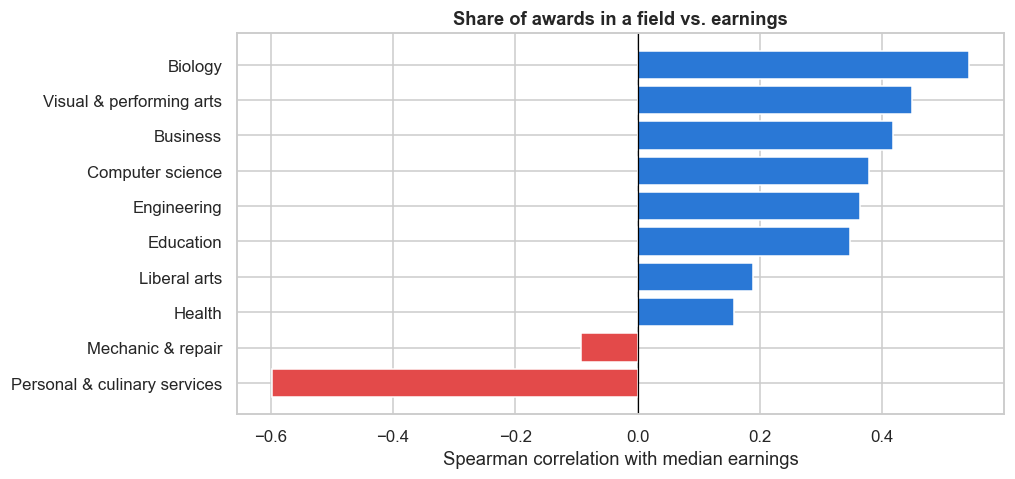

In [ ]:
CIP_NAMES = {"PCIP11": "Computer science", "PCIP14": "Engineering", "PCIP51": "Health", "PCIP52": "Business",
             "PCIP12": "Personal & culinary services", "PCIP24": "Liberal arts", "PCIP50": "Visual & performing arts",
             "PCIP13": "Education", "PCIP47": "Mechanic & repair", "PCIP26": "Biology"}
rho_cip = (eda[list(CIP_NAMES)].corrwith(eda[TARGET], method="spearman")
           .rename(index=CIP_NAMES).sort_values())

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(rho_cip.index, rho_cip.values, color=np.where(rho_cip.values < 0, "#e34a4a", "#2a78d6"))
ax.axvline(0, c="black", lw=0.8)
ax.set(title="Share of awards in a field vs. earnings", xlabel="Spearman correlation with median earnings")
save_fig("eda_programme_mix"); plt.show()

**Finding.** What a college teaches matters: a large share of awards in engineering, computer science, business or
biology goes with higher earnings, while a large share in personal and culinary services (cosmetology schools) goes
with the lowest earnings in the data. The 38 separate shares are sparse, so Section 3 groups them into a few
meaningful families.

### 2.9 Correlation matrix
Spearman (rank) correlation is used because the variables are skewed and the relationships are monotonic rather
than strictly linear; Pearson would be dominated by the outliers.

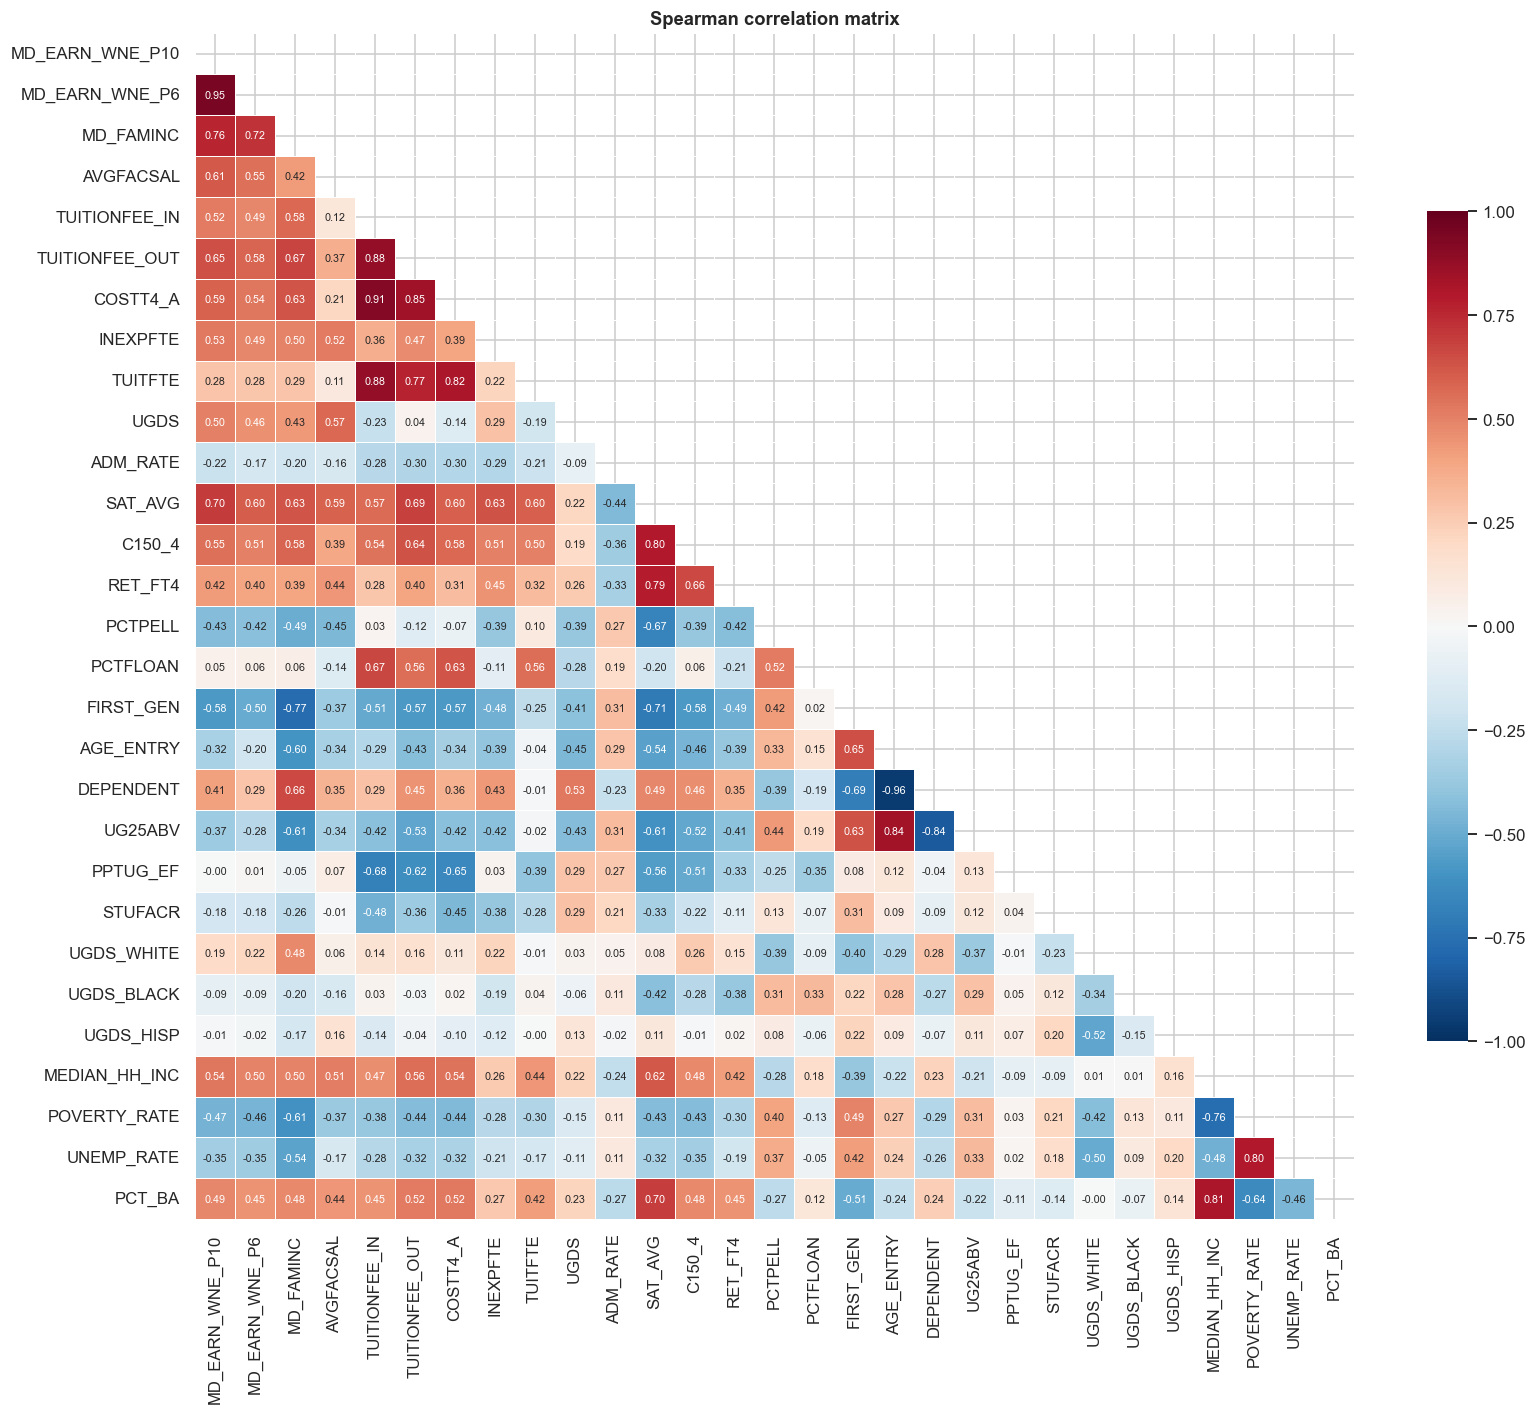

Correlation with the target (strongest first):
MD_EARN_WNE_P6    0.950
MD_FAMINC         0.760
SAT_AVG           0.700
TUITIONFEE_OUT    0.650
AVGFACSAL         0.610
COSTT4_A          0.590
FIRST_GEN        -0.580
C150_4            0.550
MEDIAN_HH_INC     0.540
INEXPFTE          0.530
TUITIONFEE_IN     0.520
UGDS              0.500
PCT_BA            0.490
POVERTY_RATE     -0.470
PCTPELL          -0.430
RET_FT4           0.420
DEPENDENT         0.410
UG25ABV          -0.370
UNEMP_RATE       -0.350
AGE_ENTRY        -0.320
TUITFTE           0.280
ADM_RATE         -0.220
UGDS_WHITE        0.190
STUFACR          -0.180
UGDS_BLACK       -0.090
PCTFLOAN          0.050
UGDS_HISP        -0.010
PPTUG_EF         -0.000


In [ ]:
CORR_VARS = [TARGET, "MD_EARN_WNE_P6", "MD_FAMINC", "AVGFACSAL", "TUITIONFEE_IN", "TUITIONFEE_OUT", "COSTT4_A",
             "INEXPFTE", "TUITFTE", "UGDS", "ADM_RATE", "SAT_AVG", "C150_4", "RET_FT4", "PCTPELL", "PCTFLOAN",
             "FIRST_GEN", "AGE_ENTRY", "DEPENDENT", "UG25ABV", "PPTUG_EF", "STUFACR", "UGDS_WHITE", "UGDS_BLACK",
             "UGDS_HISP", "MEDIAN_HH_INC", "POVERTY_RATE", "UNEMP_RATE", "PCT_BA"]
corr = eda[CORR_VARS].corr(method="spearman")

fig, ax = plt.subplots(figsize=(17, 14))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool)), cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 7}, linewidths=0.4, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Spearman correlation matrix")
save_fig("eda_correlation_matrix"); plt.show()

target_corr = corr[TARGET].drop(TARGET).sort_values(key=np.abs, ascending=False)
print("Correlation with the target (strongest first):")
print(target_corr.round(2).to_string())

In [ ]:
# Pairs of *features* that carry nearly the same information
upper = corr.drop(index=TARGET, columns=TARGET).where(np.triu(np.ones((len(corr) - 1,) * 2), k=1).astype(bool))
collinear = upper.stack().rename("spearman").reset_index().rename(columns={"level_0": "feature_a", "level_1": "feature_b"})
collinear[collinear["spearman"].abs() >= 0.85].sort_values("spearman", key=np.abs, ascending=False)

,feature_a,feature_b,spearman
312,AGE_ENTRY,DEPENDENT,-0.959
79,TUITIONFEE_IN,COSTT4_A,0.915
81,TUITIONFEE_IN,TUITFTE,0.879
78,TUITIONFEE_IN,TUITIONFEE_OUT,0.877
102,TUITIONFEE_OUT,COSTT4_A,0.851


**Findings.**
* **Leakage warning.** Earnings 6 years after entry (`MD_EARN_WNE_P6`) correlate almost perfectly with the target.
  It is the same quantity measured four years earlier, on former students, and it is unknown whenever the target
  is unknown. Using it would make the model look excellent and be useless. **All other earnings, debt-repayment
  and post-graduation outcome columns are excluded from the features.**
* **Strongest legitimate signals:** student family income, faculty salary, SAT, completion, and (negatively) the
  share of Pell and first-generation students.
* **Redundant features.** Age at entry and the share of dependent students are almost the same variable
  (rho = -0.96), and in-state and out-of-state tuition are near-duplicates. `DEPENDENT` and `TUITIONFEE_OUT`
  are therefore not used as features. Tuition, total cost and tuition revenue per student are also correlated,
  but they measure different things (sticker price, full cost, what students actually pay), so they are kept
  and the L2 part of the ElasticNet penalty is relied on to share weight among them.

### 2.10 Geography

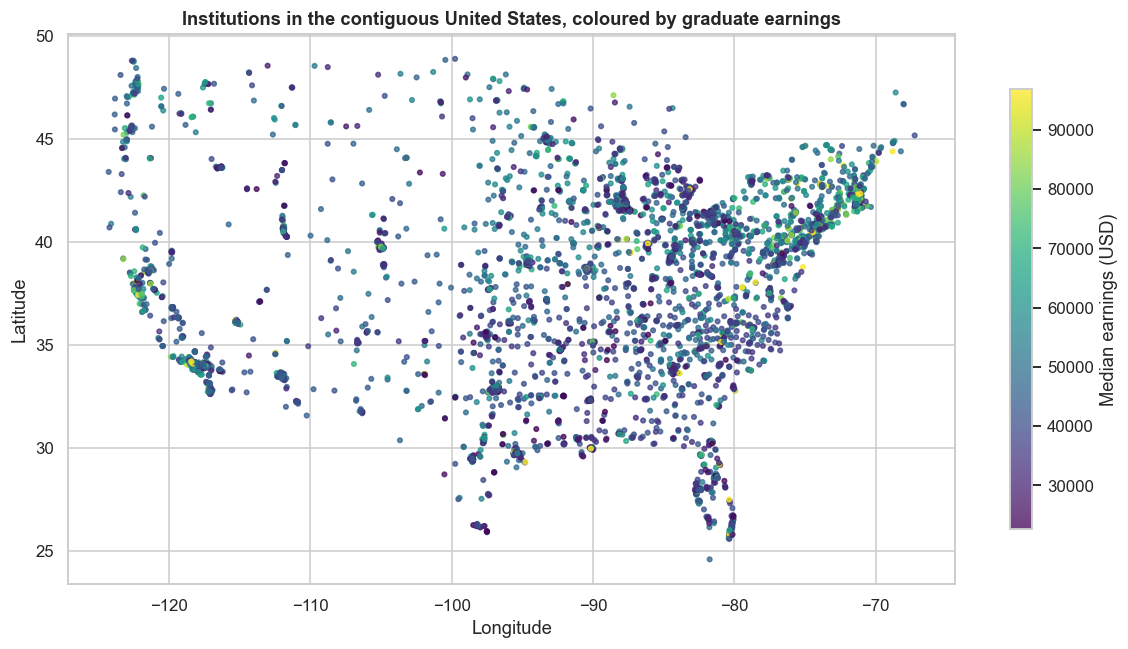

Lowest-earning states/territories : {'MH': 27651.0, 'FM': 27928.0, 'PR': 28196.0, 'MP': 29406.0}
Highest-earning states/territories: {'PA': 54779.0, 'VT': 55820.0, 'RI': 60289.0, 'MA': 62154.0}
States/territories: 59, of which 13 have fewer than 20 institutions.


In [ ]:
geo = eda[eda["LONGITUDE"].between(-125, -66) & eda["LATITUDE"].between(24, 50)]
fig, ax = plt.subplots(figsize=(13, 6.5))
sc = ax.scatter(geo["LONGITUDE"], geo["LATITUDE"], c=geo[TARGET], cmap="viridis", s=9, alpha=0.75,
                vmin=geo[TARGET].quantile(0.02), vmax=geo[TARGET].quantile(0.98))
plt.colorbar(sc, ax=ax, label="Median earnings (USD)", shrink=0.8)
ax.set(title="Institutions in the contiguous United States, coloured by graduate earnings",
       xlabel="Longitude", ylabel="Latitude")
save_fig("eda_geography"); plt.show()

state_stats = eda.groupby("STABBR")[TARGET].agg(["count", "median"]).sort_values("median")
print("Lowest-earning states/territories :", state_stats.head(4)["median"].round(0).to_dict())
print("Highest-earning states/territories:", state_stats.tail(4)["median"].round(0).to_dict())
print(f"States/territories: {len(state_stats)}, of which {(state_stats['count'] < 20).sum()} have fewer than 20 institutions.")

**Finding.** Earnings cluster geographically (higher in the North-East corridor and on the West Coast). State is a
useful feature, but with 50+ levels, many of them small, one-hot encoding would add dozens of sparse columns.
It is **target-encoded** instead (Section 3.6).

### 2.11 Anomalies and impossible combinations
The last EDA step looks for records that cannot be true. Each count below becomes a cleaning rule in Section 3.

In [ ]:
RACE_COLS = ["UGDS_WHITE", "UGDS_BLACK", "UGDS_HISP", "UGDS_ASIAN", "UGDS_AIAN",
             "UGDS_NHPI", "UGDS_2MOR", "UGDS_NRA", "UGDS_UNKN"]
race_sum = eda[RACE_COLS].sum(axis=1, min_count=1)
pcip_sum = eda[PCIP_COLS].sum(axis=1, min_count=1)
same_target = eda.groupby("OPEID6")[TARGET].transform("nunique").eq(1) & eda["OPEID6"].duplicated(keep=False)

anomalies = pd.Series({
    "Institution no longer operating (CURROPER = 0)": (eda["CURROPER"] == 0).sum(),
    "Branch rows that repeat the earnings of their parent (same OPEID6)": same_target.sum(),
    "Earnings based on fewer than 30 former students": (eda["COUNT_WNE_P10"] < 30).sum(),
    "Predominant degree not classified or graduate-only": eda["PREDDEG"].isin([0, 4]).sum(),
    "Highest degree offered lower than predominant degree": (eda["HIGHDEG"] < eda["PREDDEG"]).sum(),
    "Zero undergraduates (UGDS = 0)": (eda["UGDS"] == 0).sum(),
    "Zero or negative instructional spending / tuition revenue": ((eda["INEXPFTE"] <= 0) | (eda["TUITFTE"] <= 0)).sum(),
    "Admission rate of exactly 0": (eda["ADM_RATE"] == 0).sum(),
    "Completion rate of exactly 0": ((eda["C150_4"] == 0) | (eda["C150_L4"] == 0)).sum(),
    "'Women-only' college with more than 5 % men": ((eda["WOMENONLY"] == 1) & (eda["UGDS_MEN"] > 0.05)).sum(),
    "Race/ethnicity shares that do not add up to 1": ((race_sum - 1).abs() > 0.02).sum(),
    "Programme shares that do not add up to 1": ((pcip_sum - 1).abs() > 0.02).sum(),
    "Negative locale code (sentinel for 'not available')": (eda["LOCALE"] < 0).sum(),
    "Student-faculty ratio above 100": (eda["STUFACR"] > 100).sum(),
}, name="rows")
anomalies.to_frame()

,rows
Institution no longer operating (CURROPER = 0),62
Branch rows that repeat the earnings of their parent (same OPEID6),1623
Earnings based on fewer than 30 former students,93
Predominant degree not classified or graduate-only,431
Highest degree offered lower than predominant degree,48
Zero undergraduates (UGDS = 0),6
Zero or negative instructional spending / tuition revenue,8
Admission rate of exactly 0,2
Completion rate of exactly 0,37
'Women-only' college with more than 5 % men,3


**The most important finding of the EDA** is the second line. Earnings are computed per `OPEID6` (the federal
aid ID of an institution), and every branch campus is listed as its own row carrying **the same earnings value as
its parent**. If those rows were split at random, copies of the same target would land in both the training and the
test set and the test score would be inflated. Section 3 keeps **one row per `OPEID6`**.

## 3. Data Preparation and Feature Engineering
The order of the steps is deliberate, to prevent data leakage:

1. **Row-level cleaning** using fixed rules that do not learn anything from the data (3.1 – 3.2).
2. **Feature engineering** that only combines columns of the *same row* (3.3).
3. **Train / validation / test split** (3.4).
4. **Everything that learns from data** (which features to keep, imputation values, outlier bounds, scaling,
   encoding) is fitted on the training set only, inside a scikit-learn `Pipeline` (3.5 – 3.6).

Every cleaning rule is recorded in an audit table.

### 3.1 Cleaning: population, duplicates and unreliable records

In [ ]:
audit = []


def log_step(step, rule, before, after, unit="rows removed"):
    audit.append({"step": step, "rule": rule, "affected": before - after if unit == "rows removed" else before,
                  "unit": unit, "rows_remaining": after if unit == "rows removed" else len(clean)})


clean = df.copy()
audit.append({"step": "0", "rule": "Raw table ('PS' already converted to NaN)", "affected": n_ps_cells,
              "unit": "cells set to NaN", "rows_remaining": len(clean)})

# 1. Exact duplicates and duplicated institution IDs
n = len(clean); clean = clean.drop_duplicates().drop_duplicates(subset="UNITID")
log_step("1", "Remove exact duplicate rows / duplicated UNITID", n, len(clean))

# 2. A supervised model needs a label
n = len(clean); clean = clean[clean[TARGET].notna()]
log_step("2", "Remove rows without a target (missing or privacy-suppressed earnings)", n, len(clean))

# 3. Closed institutions are outside the population the model will serve
n = len(clean); clean = clean[clean["CURROPER"] == 1]
log_step("3", "Remove institutions that are no longer operating", n, len(clean))

# 4. Scope: undergraduate institutions. Graduate-only and unclassified rows have no undergraduate data at all
n = len(clean); clean = clean[clean["PREDDEG"].isin([1, 2, 3])]
log_step("4", "Keep predominantly certificate / associate / bachelor institutions", n, len(clean))

# 5. Earnings medians from very small cohorts are noisy labels
n = len(clean); clean = clean[clean["COUNT_WNE_P10"] >= 30]
log_step("5", "Remove rows whose earnings are based on fewer than 30 former students", n, len(clean))

# 6. One row per OPEID6: keep the main campus, or the largest campus if no main campus is listed
n = len(clean)
clean = (clean.sort_values(["OPEID6", "MAIN", "UGDS"], ascending=[True, False, False])
              .drop_duplicates(subset="OPEID6", keep="first"))
log_step("6", "De-duplicate branch campuses: one row per OPEID6 (main campus preferred)", n, len(clean))

assert clean["OPEID6"].is_unique and clean["UNITID"].is_unique
clean = clean.reset_index(drop=True)
print(f"Rows remaining: {len(clean):,}")

Rows remaining: 3,967


### 3.2 Cleaning: impossible values and impossible combinations
Impossible values are set to `NaN` rather than deleting the row: the rest of the record is still valid, and the
value is imputed later. Contradictory combinations are repaired with the more reliable of the two fields.
A median family income of exactly \$0 (rule 9) is treated the same way: it is an artefact of how income is
recorded on aid applications, not a real income, and on a log scale it would be an extreme outlier.

In [ ]:
def set_nan(mask, cols, step, rule):
    """Set `cols` to NaN where `mask` is True and record how many rows were touched."""
    cols = [cols] if isinstance(cols, str) else cols
    clean.loc[mask, cols] = np.nan
    audit.append({"step": step, "rule": rule, "affected": int(mask.sum()), "unit": "rows repaired",
                  "rows_remaining": len(clean)})


# 7. Sentinel code used for 'not available'
set_nan(clean["LOCALE"] < 0, "LOCALE", "7", "Negative locale code -> NaN")

# 8. Zero undergraduates at an operating undergraduate college
set_nan(clean["UGDS"] == 0, "UGDS", "8", "UGDS = 0 -> NaN")

# 9. Money amounts that must be strictly positive
for col in ["INEXPFTE", "TUITFTE", "AVGFACSAL", "TUITIONFEE_IN", "TUITIONFEE_OUT", "TUITIONFEE_PROG",
            "COSTT4_A", "COSTT4_P", "MD_FAMINC", "MEDIAN_HH_INC"]:
    set_nan(clean[col] <= 0, col, "9", f"{col} <= 0 -> NaN")

# 10. Proportions must lie in [0, 1]
PROPORTION_COLS = (RACE_COLS + PCIP_COLS + ["UGDS_MEN", "UGDS_WOMEN", "PPTUG_EF", "UG25ABV", "PCTPELL", "PCTFLOAN",
                                            "ADM_RATE", "C150_4", "C150_L4", "RET_FT4", "RET_FTL4", "PFTFAC",
                                            "FIRST_GEN", "DEPENDENT", "MARRIED"])
out_of_range = sum(int(((clean[c] < 0) | (clean[c] > 1)).sum()) for c in PROPORTION_COLS)
for c in PROPORTION_COLS:
    clean.loc[(clean[c] < 0) | (clean[c] > 1), c] = np.nan
audit.append({"step": "10", "rule": "Proportion outside [0, 1] -> NaN", "affected": out_of_range,
              "unit": "cells set to NaN", "rows_remaining": len(clean)})

# 11. Rates of exactly zero that cannot be true for an operating college with an earnings cohort
set_nan(clean["ADM_RATE"] == 0, "ADM_RATE", "11", "Admission rate = 0 -> NaN")
set_nan(clean["C150_4"] == 0, "C150_4", "11", "4-year completion rate = 0 -> NaN")
set_nan(clean["C150_L4"] == 0, "C150_L4", "11", "Less-than-4-year completion rate = 0 -> NaN")

# 12. Shares that should add up to 1 but do not: the whole block is unreliable
race_sum = clean[RACE_COLS].sum(axis=1, min_count=1)
set_nan((race_sum - 1).abs() > 0.02, RACE_COLS, "12", "Race/ethnicity shares do not sum to 1 -> NaN")
sex_sum = clean[["UGDS_MEN", "UGDS_WOMEN"]].sum(axis=1, min_count=1)
set_nan((sex_sum - 1).abs() > 0.02, ["UGDS_MEN", "UGDS_WOMEN"], "12", "Men + women shares do not sum to 1 -> NaN")
pcip_sum = clean[PCIP_COLS].sum(axis=1, min_count=1)
set_nan((pcip_sum - 1).abs() > 0.02, PCIP_COLS, "12", "Programme shares do not sum to 1 -> NaN")

# 13. Highest degree cannot be lower than the predominant degree -> raise it to the predominant degree
mask = clean["HIGHDEG"] < clean["PREDDEG"]
clean.loc[mask, "HIGHDEG"] = clean.loc[mask, "PREDDEG"]
audit.append({"step": "13", "rule": "HIGHDEG < PREDDEG -> HIGHDEG = PREDDEG", "affected": int(mask.sum()),
              "unit": "rows repaired", "rows_remaining": len(clean)})

# 14. Single-sex flag contradicted by enrolment -> trust the enrolment counts
for flag, other in [("WOMENONLY", "UGDS_MEN"), ("MENONLY", "UGDS_WOMEN")]:
    mask = (clean[flag] == 1) & (clean[other] > 0.05)
    clean.loc[mask, flag] = 0
    audit.append({"step": "14", "rule": f"{flag} = 1 but {other} > 5 % -> flag set to 0", "affected": int(mask.sum()),
                  "unit": "rows repaired", "rows_remaining": len(clean)})

# 15. Out-of-state tuition below in-state tuition is impossible
set_nan(clean["TUITIONFEE_OUT"] < clean["TUITIONFEE_IN"], "TUITIONFEE_OUT", "15", "Out-of-state < in-state tuition -> NaN")

audit_df = pd.DataFrame(audit)
audit_df = audit_df[(audit_df["affected"] > 0) | (audit_df["unit"] == "rows removed")].reset_index(drop=True)
audit_df.to_csv(REPORTS_DIR / "cleaning_audit.csv", index=False)
audit_df

,step,rule,affected,unit,rows_remaining
0,0,Raw table ('PS' already converted to NaN),4311,cells set to NaN,6272
1,1,Remove exact duplicate rows / duplicated UNITID,0,rows removed,6272
2,2,Remove rows without a target (missing or priva...,983,rows removed,5289
3,3,Remove institutions that are no longer operating,62,rows removed,5227
4,4,Keep predominantly certificate / associate / b...,411,rows removed,4816
5,5,Remove rows whose earnings are based on fewer ...,85,rows removed,4731
6,6,De-duplicate branch campuses: one row per OPEI...,764,rows removed,3967
7,7,Negative locale code -> NaN,2,rows repaired,3967
8,8,UGDS = 0 -> NaN,4,rows repaired,3967
9,9,INEXPFTE <= 0 -> NaN,1,rows repaired,3967


### 3.3 Feature engineering
New features are built from domain knowledge. Each one only uses values from its own row, so doing this before the
split cannot leak information.

| Engineered feature | How | Why |
|---|---|---|
| `NET_PRICE`, `COMPLETION_RATE`, `RETENTION_RATE`, `COST_ATTEND`, `TUITION` | Merge each public/private or 4-year/shorter pair into one column | Removes structural missingness found in 2.2 |
| `ADM_RATE_FILLED`, `OPEN_ADMISSION` | Admission rate set to 1.0 for open-admission colleges | Those colleges admit everyone; the value is known, not missing |
| `STEM_SHARE`, `HEALTH_SHARE`, `BUSINESS_SHARE`, `TRADES_SHARE`, `ARTS_HUM_SHARE`, `EDU_SOCIAL_SHARE` | Sum the 38 sparse programme shares into 6 families | Programme mix drives earnings (2.8); 6 dense features are more learnable than 38 sparse ones |
| `PROGRAM_HHI` | Sum of squared programme shares (Herfindahl index) | Measures specialisation: 1 = single-programme school, near 0 = comprehensive university |
| `INSTR_PER_TUITION` | Instructional spending ÷ tuition revenue, per student | How much of what students pay is spent on teaching them |
| `LOCALE_TYPE` | First digit of the 12-level locale code → City / Suburb / Town / Rural | Keeps the urban–rural signal with 4 levels instead of 12 |
| `SINGLE_SEX`, `MULTI_CAMPUS` | Combine rare flags; `NUMBRANCH > 1` | Rare binary flags are merged so they are not almost-constant columns |

In [ ]:
fe = clean.copy()

# Merge complementary pairs (exactly one of the two is filled for each institution)
fe["NET_PRICE"] = fe["NPT4_PUB"].fillna(fe["NPT4_PRIV"])
fe["COMPLETION_RATE"] = fe["C150_4"].fillna(fe["C150_L4"])
fe["RETENTION_RATE"] = fe["RET_FT4"].fillna(fe["RET_FTL4"])
fe["COST_ATTEND"] = fe["COSTT4_A"].fillna(fe["COSTT4_P"])
fe["TUITION"] = fe["TUITIONFEE_IN"].fillna(fe["TUITIONFEE_PROG"])

# Admissions: an open-admission college admits every applicant
fe["OPEN_ADMISSION"] = fe["OPENADMP"].map({1: 1.0, 2: 0.0})
fe["ADM_RATE_FILLED"] = fe["ADM_RATE"].where(fe["ADM_RATE"].notna() | (fe["OPEN_ADMISSION"] != 1), 1.0)

# Programme mix: 38 CIP shares -> 6 families + concentration index
CIP_FAMILIES = {
    "STEM_SHARE": ["PCIP11", "PCIP14", "PCIP15", "PCIP26", "PCIP27", "PCIP40", "PCIP41"],
    "HEALTH_SHARE": ["PCIP51"],
    "BUSINESS_SHARE": ["PCIP52"],
    "TRADES_SHARE": ["PCIP12", "PCIP46", "PCIP47", "PCIP48", "PCIP49"],
    "ARTS_HUM_SHARE": ["PCIP16", "PCIP23", "PCIP24", "PCIP38", "PCIP39", "PCIP50", "PCIP54"],
    "EDU_SOCIAL_SHARE": ["PCIP13", "PCIP19", "PCIP42", "PCIP44", "PCIP45"],
}
for name, cols in CIP_FAMILIES.items():
    fe[name] = fe[cols].sum(axis=1, min_count=1)
fe["PROGRAM_HHI"] = (fe[PCIP_COLS] ** 2).sum(axis=1, min_count=1)

# Finance ratio
fe["INSTR_PER_TUITION"] = fe["INEXPFTE"] / fe["TUITFTE"]

# Institution flags
fe["SINGLE_SEX"] = ((fe["MENONLY"] == 1) | (fe["WOMENONLY"] == 1)).astype(float)
fe.loc[fe["MENONLY"].isna() & fe["WOMENONLY"].isna(), "SINGLE_SEX"] = np.nan
fe["MULTI_CAMPUS"] = (fe["NUMBRANCH"] > 1).astype(float)

# Readable category labels (also used by the Streamlit app)
LOCALE_TYPE_MAP = {1: "City", 2: "Suburb", 3: "Town", 4: "Rural"}
fe["LOCALE_TYPE"] = (fe["LOCALE"] // 10).map(LOCALE_TYPE_MAP)
fe["CONTROL"] = fe["CONTROL"].map(CONTROL_MAP)
fe["PREDDEG"] = fe["PREDDEG"].map(PREDDEG_MAP)
fe["REGION"] = fe["REGION"].map(REGION_MAP)

engineered = ["NET_PRICE", "COMPLETION_RATE", "RETENTION_RATE", "COST_ATTEND", "TUITION", "ADM_RATE_FILLED",
              *CIP_FAMILIES, "PROGRAM_HHI", "INSTR_PER_TUITION"]
before_after = pd.DataFrame({
    "built from": ["NPT4_PUB | NPT4_PRIV", "C150_4 | C150_L4", "RET_FT4 | RET_FTL4", "COSTT4_A | COSTT4_P",
                   "TUITIONFEE_IN | TUITIONFEE_PROG", "ADM_RATE + OPENADMP", *["PCIP*"] * 7, "INEXPFTE / TUITFTE"],
    "missing_% of best source": [fe[["NPT4_PUB", "NPT4_PRIV"]].isna().mean().min() * 100,
                                 fe[["C150_4", "C150_L4"]].isna().mean().min() * 100,
                                 fe[["RET_FT4", "RET_FTL4"]].isna().mean().min() * 100,
                                 fe[["COSTT4_A", "COSTT4_P"]].isna().mean().min() * 100,
                                 fe["TUITIONFEE_IN"].isna().mean() * 100, fe["ADM_RATE"].isna().mean() * 100,
                                 *[fe[PCIP_COLS[0]].isna().mean() * 100] * 7, fe["INEXPFTE"].isna().mean() * 100],
    "missing_% engineered": fe[engineered].isna().mean().values * 100,
    "spearman with target": fe[engineered].corrwith(fe[TARGET], method="spearman").values,
}, index=engineered).round(2)
before_after

,built from,missing_% of best source,missing_% engineered,spearman with target
NET_PRICE,NPT4_PUB | NPT4_PRIV,46.960,5.320,0.310
COMPLETION_RATE,C150_4 | C150_L4,51.750,3.600,0.030
RETENTION_RATE,RET_FT4 | RET_FTL4,52.260,9.430,0.130
COST_ATTEND,COSTT4_A | COSTT4_P,30.980,4.740,0.520
TUITION,TUITIONFEE_IN | TUITIONFEE_PROG,30.120,2.090,0.360
ADM_RATE_FILLED,ADM_RATE + OPENADMP,59.520,2.020,-0.620
STEM_SHARE,PCIP*,0.150,0.150,0.490
HEALTH_SHARE,PCIP*,0.150,0.150,0.150
BUSINESS_SHARE,PCIP*,0.150,0.150,0.410
TRADES_SHARE,PCIP*,0.150,0.150,-0.620


Merging the pairs cuts their missing share from roughly a half to under 10 %, and the engineered programme
families are among the features most correlated with earnings (`TRADES_SHARE` and `STEM_SHARE` in particular).

**A caution about `COMPLETION_RATE`.** On its own it shows almost no correlation with earnings, although the
4-year rate alone was clearly positive in Section 2.9. The reason is that short certificate programmes have
*high* completion and *low* earnings, which cancels the positive relationship inside each degree level. The
feature is only informative **together with `PREDDEG`**, an interaction that tree and kernel models can learn
and a linear model cannot.

#### Candidate feature set
Only characteristics that are known **before** earnings are observed are used. Identifiers, coordinates and every
earnings-related column are excluded.

In [ ]:
NUMERIC_CANDIDATES = [
    # size and structure
    "UGDS", "NUMBRANCH", "PPTUG_EF", "UG25ABV",
    # student body
    "PCTPELL", "PCTFLOAN", "UGDS_WOMEN", "UGDS_WHITE", "UGDS_BLACK", "UGDS_HISP", "UGDS_ASIAN", "UGDS_NRA",
    # cost and finance
    "TUITION", "COST_ATTEND", "NET_PRICE", "TUITFTE", "INEXPFTE", "INSTR_PER_TUITION", "AVGFACSAL", "PFTFAC", "STUFACR",
    # selectivity and academic progress
    "ADM_RATE_FILLED", "SAT_AVG", "COMPLETION_RATE", "RETENTION_RATE",
    # student background (aid and tax records)
    "MD_FAMINC", "FIRST_GEN", "AGE_ENTRY", "MARRIED",
    # economy of students' home areas
    "MEDIAN_HH_INC", "POVERTY_RATE", "UNEMP_RATE", "PCT_BA",
    # programme mix
    "STEM_SHARE", "HEALTH_SHARE", "BUSINESS_SHARE", "TRADES_SHARE", "ARTS_HUM_SHARE", "EDU_SOCIAL_SHARE", "PROGRAM_HHI",
]
BINARY_FEATURES = ["HBCU", "DISTANCEONLY", "OPEN_ADMISSION", "SINGLE_SEX", "MULTI_CAMPUS"]
ORDINAL_FEATURES = ["HIGHDEG"]                       # 1 certificate < 2 associate < 3 bachelor < 4 graduate
ONEHOT_FEATURES = ["CONTROL", "PREDDEG", "REGION", "LOCALE_TYPE"]
TARGET_ENC_FEATURES = ["STABBR"]
ID_COLS = ["UNITID", "OPEID6", "INSTNM", "CITY", "STABBR", "LATITUDE", "LONGITUDE"]

ALL_CANDIDATES = NUMERIC_CANDIDATES + BINARY_FEATURES + ORDINAL_FEATURES + ONEHOT_FEATURES + TARGET_ENC_FEATURES
model_table = fe[ID_COLS + [c for c in ALL_CANDIDATES if c not in ID_COLS] + ["COUNT_WNE_P10", TARGET]].copy()

print(f"Modelling table: {model_table.shape[0]:,} institutions, {len(ALL_CANDIDATES)} candidate features")
model_table[ALL_CANDIDATES + [TARGET]].head()

Modelling table: 3,967 institutions, 51 candidate features


,UGDS,NUMBRANCH,PPTUG_EF,UG25ABV,PCTPELL,PCTFLOAN,UGDS_WOMEN,UGDS_WHITE,UGDS_BLACK,UGDS_HISP,UGDS_ASIAN,UGDS_NRA,TUITION,COST_ATTEND,NET_PRICE,TUITFTE,INEXPFTE,INSTR_PER_TUITION,AVGFACSAL,PFTFAC,STUFACR,ADM_RATE_FILLED,SAT_AVG,COMPLETION_RATE,RETENTION_RATE,MD_FAMINC,FIRST_GEN,AGE_ENTRY,MARRIED,MEDIAN_HH_INC,POVERTY_RATE,UNEMP_RATE,PCT_BA,STEM_SHARE,HEALTH_SHARE,BUSINESS_SHARE,TRADES_SHARE,ARTS_HUM_SHARE,EDU_SOCIAL_SHARE,PROGRAM_HHI,HBCU,DISTANCEONLY,OPEN_ADMISSION,SINGLE_SEX,MULTI_CAMPUS,HIGHDEG,CONTROL,PREDDEG,REGION,LOCALE_TYPE,STABBR,MD_EARN_WNE_P10
0,"6,124.000",1,0.074,0.071,0.642,0.771,0.578,0.016,0.901,0.021,0.002,0.024,"10,558.000","27,732.000","18,255.000","7,729.000","7,254.000",0.939,"8,699.000",0.644,19.000,0.580,938.000,0.277,0.699,"23,553.000",0.366,20.284,0.009,"49,720.220",14.880,4.840,13.000,0.326,0.000,0.169,0.000,0.111,0.184,0.083,1.000,0.000,0.000,0.000,0.000,4,Public,Bachelor,Southeast,City,AL,"41,266.000"
1,"1,549.000",1,0.257,0.409,0.550,0.507,0.558,0.444,0.385,0.055,0.009,0.049,"26,590.000","37,209.000","23,416.000","14,131.000","8,533.000",0.604,"7,049.000",0.601,14.000,0.731,"1,020.000",0.371,0.645,"24,037.500",0.430,28.260,0.168,"52,330.990",12.310,3.920,14.550,0.028,0.057,0.458,0.000,0.040,0.097,0.275,0.000,0.000,0.000,0.000,0.000,4,Private nonprofit,Bachelor,Southeast,City,AL,"48,627.000"
2,"2,151.000",1,0.061,0.060,0.359,0.399,0.595,0.647,0.161,0.075,0.006,0.039,"14,416.000","29,520.000","18,760.000","7,645.000","15,957.000",2.087,"9,085.000",0.711,13.000,0.538,NaN,0.556,0.728,"43,813.000",0.325,21.024,0.039,"59,047.150",9.340,2.950,15.840,0.079,0.047,0.221,0.000,0.300,0.194,0.116,0.000,0.000,0.000,0.000,0.000,4,Public,Bachelor,Southeast,Town,AL,"46,010.000"
3,"3,477.000",1,0.067,0.069,0.720,0.789,0.635,0.018,0.863,0.014,0.002,0.025,"11,248.000","23,655.000","9,775.000","9,820.000","10,723.000",1.092,"8,153.000",0.648,15.000,0.976,976.000,0.307,0.698,"22,080.500",0.343,20.131,0.008,"46,065.200",16.960,4.810,11.810,0.231,0.058,0.100,0.000,0.106,0.229,0.085,1.000,0.000,0.000,0.000,0.000,4,Public,Bachelor,Southeast,City,AL,"40,585.000"
4,"1,203.000",1,0.535,0.179,0.312,0.161,0.661,0.622,0.268,0.052,0.006,0.003,"5,520.000","15,709.000","8,615.000","2,577.000","8,630.000",3.349,"7,001.000",0.429,16.000,1.000,NaN,0.285,0.599,"22,217.000",0.550,23.071,0.096,"43,985.140",13.550,3.760,7.970,0.099,0.211,0.054,0.360,0.229,0.013,0.172,0.000,0.000,1.000,0.000,0.000,2,Public,Certificate,Southeast,Town,AL,"37,682.000"


### 3.4 Train / validation / test split
* **70 % train** – fit preprocessing and models; hyperparameters are tuned here with 5-fold cross-validation.
* **15 % validation** – choose the final model among the tuned candidates.
* **15 % test** – touched once, at the very end, to report performance.

The split is **stratified on earnings quintiles** so that all three sets cover the full range of the target, which
matters for a skewed target and a small test set. Because each `OPEID6` now appears exactly once, no institution
can be in two sets.

In [ ]:
X = model_table[ALL_CANDIDATES]
y = model_table[TARGET]
meta = model_table[["UNITID", "OPEID6", "INSTNM", "STABBR"]]
strata = pd.qcut(y, q=5, labels=False)

X_train, X_tmp, y_train, y_tmp, strata_train, strata_tmp = train_test_split(
    X, y, strata, test_size=0.30, stratify=strata, random_state=RANDOM_STATE)
X_val, X_test, y_val, y_test = train_test_split(
    X_tmp, y_tmp, test_size=0.50, stratify=strata_tmp, random_state=RANDOM_STATE)

# Leakage checks: no row and no institution appears in more than one set
ids = {name: set(meta.loc[idx, "OPEID6"]) for name, idx in
       [("train", X_train.index), ("val", X_val.index), ("test", X_test.index)]}
assert not (ids["train"] & ids["val"]) and not (ids["train"] & ids["test"]) and not (ids["val"] & ids["test"])

split_summary = pd.DataFrame({name: {"rows": len(t), "share": len(t) / len(y), "mean": t.mean(),
                                     "median": t.median(), "std": t.std(), "min": t.min(), "max": t.max()}
                              for name, t in [("train", y_train), ("validation", y_val), ("test", y_test)]}).T
split_summary

,rows,share,mean,median,std,min,max
train,"2,776.000",0.700,"49,442.689","46,584.000","17,621.921","15,462.000","166,642.000"
validation,595.000,0.150,"49,366.709","46,594.000","17,154.118","14,374.000","109,954.000"
test,596.000,0.150,"49,956.320","46,318.500","19,019.655","17,252.000","138,950.000"


### 3.5 Missing values, skewness and outliers (decided on the training set only)
**Missing values – programmatic rule.**
1. A feature with more than **50 %** missing values in the training set is dropped: more than half of its values
   would be invented by the imputer.
2. Remaining numeric features are imputed with the **training median** (robust to the skew seen in 2.3), and a
   **missing-indicator** column is added, because missingness is informative here (privacy suppression and
   non-reporting happen at small, specialised colleges).
3. Categorical features get an explicit `"Missing"` level; binary flags get the most frequent value.

Rows are **not** dropped for missing features: only a minority of institutions are complete on every feature, and
they are not a random sample.

In [ ]:
MISSING_THRESHOLD = 0.50
train_missing = X_train.isna().mean().sort_values(ascending=False)
dropped_features = train_missing[train_missing > MISSING_THRESHOLD].index.tolist()

NUMERIC_FEATURES = [c for c in NUMERIC_CANDIDATES if c not in dropped_features]
FEATURES = [c for c in ALL_CANDIDATES if c not in dropped_features]

print(f"Dropped (> {MISSING_THRESHOLD:.0%} missing in train): {dropped_features}")
print(f"Features kept: {len(FEATURES)}  ({len(NUMERIC_FEATURES)} numeric, {len(BINARY_FEATURES)} binary, "
      f"{len(ORDINAL_FEATURES)} ordinal, {len(ONEHOT_FEATURES)} one-hot, {len(TARGET_ENC_FEATURES)} target-encoded)")
print(f"Training rows complete on every kept feature: {X_train[FEATURES].notna().all(axis=1).mean():.1%}")
train_missing.head(12).mul(100).round(1).rename("missing_% (train)").to_frame().T

Dropped (> 50% missing in train): ['SAT_AVG']
Features kept: 50  (39 numeric, 5 binary, 1 ordinal, 4 one-hot, 1 target-encoded)
Training rows complete on every kept feature: 51.7%


,SAT_AVG,PFTFAC,AVGFACSAL,MARRIED,PCT_BA,MEDIAN_HH_INC,POVERTY_RATE,UNEMP_RATE,RETENTION_RATE,FIRST_GEN,NET_PRICE,COST_ATTEND
missing_% (train),75.400,29.100,26.300,12.500,11.600,11.000,11.000,11.000,9.000,8.800,5.400,4.900


**Skewness – programmatic rule.** Among features measured in dollars or counts, those with a training skewness
above 1 get a `log1p` transform. Proportions are bounded in [0, 1] and are left as they are.

**Outliers – programmatic rule.** Outlying *feature* values are **winsorised**: capped at the 1st and 99th
percentile of the training data (`Winsorizer`, in `src/transformers.py`). Capping keeps every institution, unlike
deletion, and limits the leverage of extreme values on the linear and kernel models. The 1.5 × IQR rule was
considered and rejected: on these long-tailed features it would flag a large share of perfectly real institutions
(see the table below). Outliers in the *target* are kept and handled by the log transform (2.4).

In [ ]:
AMOUNT_FEATURES = [c for c in ["UGDS", "NUMBRANCH", "TUITION", "COST_ATTEND", "NET_PRICE", "TUITFTE", "INEXPFTE",
                               "INSTR_PER_TUITION", "AVGFACSAL", "STUFACR", "MD_FAMINC", "MEDIAN_HH_INC"]
                   if c in NUMERIC_FEATURES]
train_skew = X_train[AMOUNT_FEATURES].skew()
LOG_FEATURES = train_skew[train_skew > 1].index.tolist()
LINEAR_FEATURES = [c for c in NUMERIC_FEATURES if c not in LOG_FEATURES]

q = X_train[NUMERIC_FEATURES].quantile([0.01, 0.25, 0.75, 0.99]).T
iqr = q[0.75] - q[0.25]
outlier_tbl = pd.DataFrame({
    "skew (train)": X_train[NUMERIC_FEATURES].skew(),
    "log1p applied": [c in LOG_FEATURES for c in NUMERIC_FEATURES],
    "p01": q[0.01], "p99": q[0.99], "max": X_train[NUMERIC_FEATURES].max(),
    "% outside 1.5xIQR": ((X_train[NUMERIC_FEATURES] < q[0.25] - 1.5 * iqr) |
                          (X_train[NUMERIC_FEATURES] > q[0.75] + 1.5 * iqr)).mean() * 100,
    "% capped by winsorizer": ((X_train[NUMERIC_FEATURES] < q[0.01]) | (X_train[NUMERIC_FEATURES] > q[0.99])).mean() * 100,
}).round(2).sort_values("skew (train)", ascending=False)
print("Log-transformed features:", LOG_FEATURES)
outlier_tbl.head(14)

Log-transformed features: ['UGDS', 'NUMBRANCH', 'TUITION', 'COST_ATTEND', 'TUITFTE', 'INEXPFTE', 'INSTR_PER_TUITION', 'AVGFACSAL', 'STUFACR', 'MD_FAMINC']


,skew (train),log1p applied,p01,p99,max,% outside 1.5xIQR,% capped by winsorizer
INSTR_PER_TUITION,46.240,True,0.100,21.470,"1,404.710",10.730,2.020
NUMBRANCH,9.790,True,1.000,7.250,31.000,9.940,1.010
INEXPFTE,8.620,True,"1,146.100","45,124.020","240,771.000",6.050,2.020
UGDS,7.120,True,22.000,"32,800.330","155,088.000",11.100,1.770
STUFACR,6.800,True,3.710,36.000,191.000,2.050,1.980
UGDS_NRA,6.530,False,0.000,0.280,0.950,9.980,1.010
UGDS_ASIAN,4.740,False,0.000,0.340,0.950,10.410,1.010
POVERTY_RATE,3.210,False,4.120,39.600,53.240,4.430,1.800
STEM_SHARE,2.760,False,0.000,0.590,1.000,3.960,1.010
UNEMP_RATE,2.510,False,2.260,8.240,14.970,4.860,1.730


### 3.6 Encoding, scaling and the preprocessing pipeline
| Feature type | Treatment | Why |
|---|---|---|
| Skewed amounts | `log1p` → winsorise → standardise → median-impute + indicator | Compress the right tail first, then cap what is left |
| Other numeric | winsorise → standardise → median-impute + indicator | |
| Binary flags | most-frequent imputation | Already 0/1 |
| `HIGHDEG` | **ordinal (label) encoding** 1 < 2 < 3 < 4 | The levels have a natural order |
| `CONTROL`, `PREDDEG`, `REGION`, `LOCALE_TYPE` | **one-hot encoding** | Few levels, no order; one-hot avoids inventing one |
| `STABBR` (50+ levels) | **target encoding**, then standardise | One-hot would add 50+ sparse columns. scikit-learn's `TargetEncoder` uses internal cross-fitting and smoothing, so a row's own target never enters its encoding |

**Scaling.** `StandardScaler` (zero mean, unit variance) is used rather than `MinMaxScaler`: min-max depends on the
two most extreme points, while ElasticNet (penalty on coefficient size) and SVR (distances) need features on a
comparable scale and are better served by standardisation after the tails are capped. Tree models do not need
scaling, but the same preprocessing is used for all models so that the comparison is like-for-like.

Standardising before imputing means the median is imputed in standardised units and the missing indicators stay 0/1.
Everything is inside one `ColumnTransformer`, so during cross-validation each step is re-fitted on the training
folds only.

In [ ]:
def make_preprocessor():
    """Return a fresh, unfitted preprocessing ColumnTransformer."""
    log_numeric = Pipeline([
        ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        ("winsor", Winsorizer(0.01, 0.99)),
        ("scale", StandardScaler()),
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
    ])
    numeric = Pipeline([
        ("winsor", Winsorizer(0.01, 0.99)),
        ("scale", StandardScaler()),
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
    ])
    binary = SimpleImputer(strategy="most_frequent")
    ordinal = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("encode", OrdinalEncoder(categories=[[1, 2, 3, 4]], handle_unknown="use_encoded_value", unknown_value=-1)),
    ])
    onehot = Pipeline([
        ("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
        ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    target_enc = Pipeline([
        ("encode", TargetEncoder(target_type="continuous", smooth="auto", cv=5, random_state=RANDOM_STATE)),
        ("scale", StandardScaler()),
    ])
    return ColumnTransformer([
        ("log_num", log_numeric, LOG_FEATURES),
        ("num", numeric, LINEAR_FEATURES),
        ("bin", binary, BINARY_FEATURES),
        ("ord", ordinal, ORDINAL_FEATURES),
        ("ohe", onehot, ONEHOT_FEATURES),
        ("tgt", target_enc, TARGET_ENC_FEATURES),
    ], remainder="drop", verbose_feature_names_out=False)


X_train, X_val, X_test = X_train[FEATURES], X_val[FEATURES], X_test[FEATURES]

# Fit once on the training set to inspect the result (the models below refit it inside their own pipeline)
demo_prep = make_preprocessor().fit(X_train, np.log(y_train))
Xt_train = pd.DataFrame(demo_prep.transform(X_train), columns=demo_prep.get_feature_names_out(), index=X_train.index)
print(f"Before preprocessing: {X_train.shape[1]} columns, {int(X_train.isna().sum().sum()):,} missing cells")
print(f"After  preprocessing: {Xt_train.shape[1]} columns, {int(Xt_train.isna().sum().sum())} missing cells")
Xt_train.head()

Before preprocessing: 50 columns, 4,329 missing cells
After  preprocessing: 104 columns, 0 missing cells


,UGDS,NUMBRANCH,TUITION,COST_ATTEND,TUITFTE,INEXPFTE,INSTR_PER_TUITION,AVGFACSAL,STUFACR,MD_FAMINC,missingindicator_UGDS,missingindicator_TUITION,missingindicator_COST_ATTEND,missingindicator_TUITFTE,missingindicator_INEXPFTE,missingindicator_INSTR_PER_TUITION,missingindicator_AVGFACSAL,missingindicator_STUFACR,missingindicator_MD_FAMINC,PPTUG_EF,UG25ABV,PCTPELL,PCTFLOAN,UGDS_WOMEN,UGDS_WHITE,UGDS_BLACK,UGDS_HISP,UGDS_ASIAN,UGDS_NRA,NET_PRICE,...,missingindicator_ARTS_HUM_SHARE,missingindicator_EDU_SOCIAL_SHARE,missingindicator_PROGRAM_HHI,HBCU,DISTANCEONLY,OPEN_ADMISSION,SINGLE_SEX,MULTI_CAMPUS,HIGHDEG,CONTROL_Private for-profit,CONTROL_Private nonprofit,CONTROL_Public,PREDDEG_Associate,PREDDEG_Bachelor,PREDDEG_Certificate,REGION_Far West,REGION_Great Lakes,REGION_Mid East,REGION_New England,REGION_Outlying Areas,REGION_Plains,REGION_Rocky Mountains,REGION_Southeast,REGION_Southwest,LOCALE_TYPE_City,LOCALE_TYPE_Missing,LOCALE_TYPE_Rural,LOCALE_TYPE_Suburb,LOCALE_TYPE_Town,STABBR
2941,-1.096,-0.292,0.655,0.153,0.242,-1.416,-0.903,-0.012,1.625,-0.655,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,-0.948,0.087,0.071,0.119,1.622,0.439,-0.139,-0.167,-0.291,-0.540,0.119,...,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,-0.055
3660,0.749,-0.292,-2.285,-0.217,-2.911,-0.615,2.708,1.478,1.795,-0.486,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.325,-0.158,0.161,-1.399,-0.009,-1.250,-0.625,2.357,-0.031,-0.527,-0.571,...,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,1.000,0.000,0.000,1.000,1.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.502
1762,0.768,-0.292,1.142,1.223,0.484,-0.154,-0.610,0.015,0.549,0.815,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,-0.182,-0.712,-0.400,0.216,-0.257,-0.537,-0.199,-0.191,0.077,3.528,1.170,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,3.000,0.000,1.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,1.000,0.000,0.000,0.000,0.000,-1.399
806,1.238,-0.292,-1.577,-1.214,-0.683,0.107,0.492,0.372,0.679,-0.408,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.729,0.349,-0.628,-0.893,-0.401,0.424,0.072,-0.539,-0.088,-0.089,-1.435,...,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,1.000,0.000,0.000,1.000,0.000,0.000,1.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,-0.660
1388,0.972,1.422,1.552,1.776,1.142,0.647,-0.666,1.099,-0.621,2.271,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,-0.847,-1.238,-1.021,0.683,-0.428,0.828,-0.515,-0.495,0.840,-0.076,1.629,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,3.000,0.000,1.000,0.000,0.000,1.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,1.212


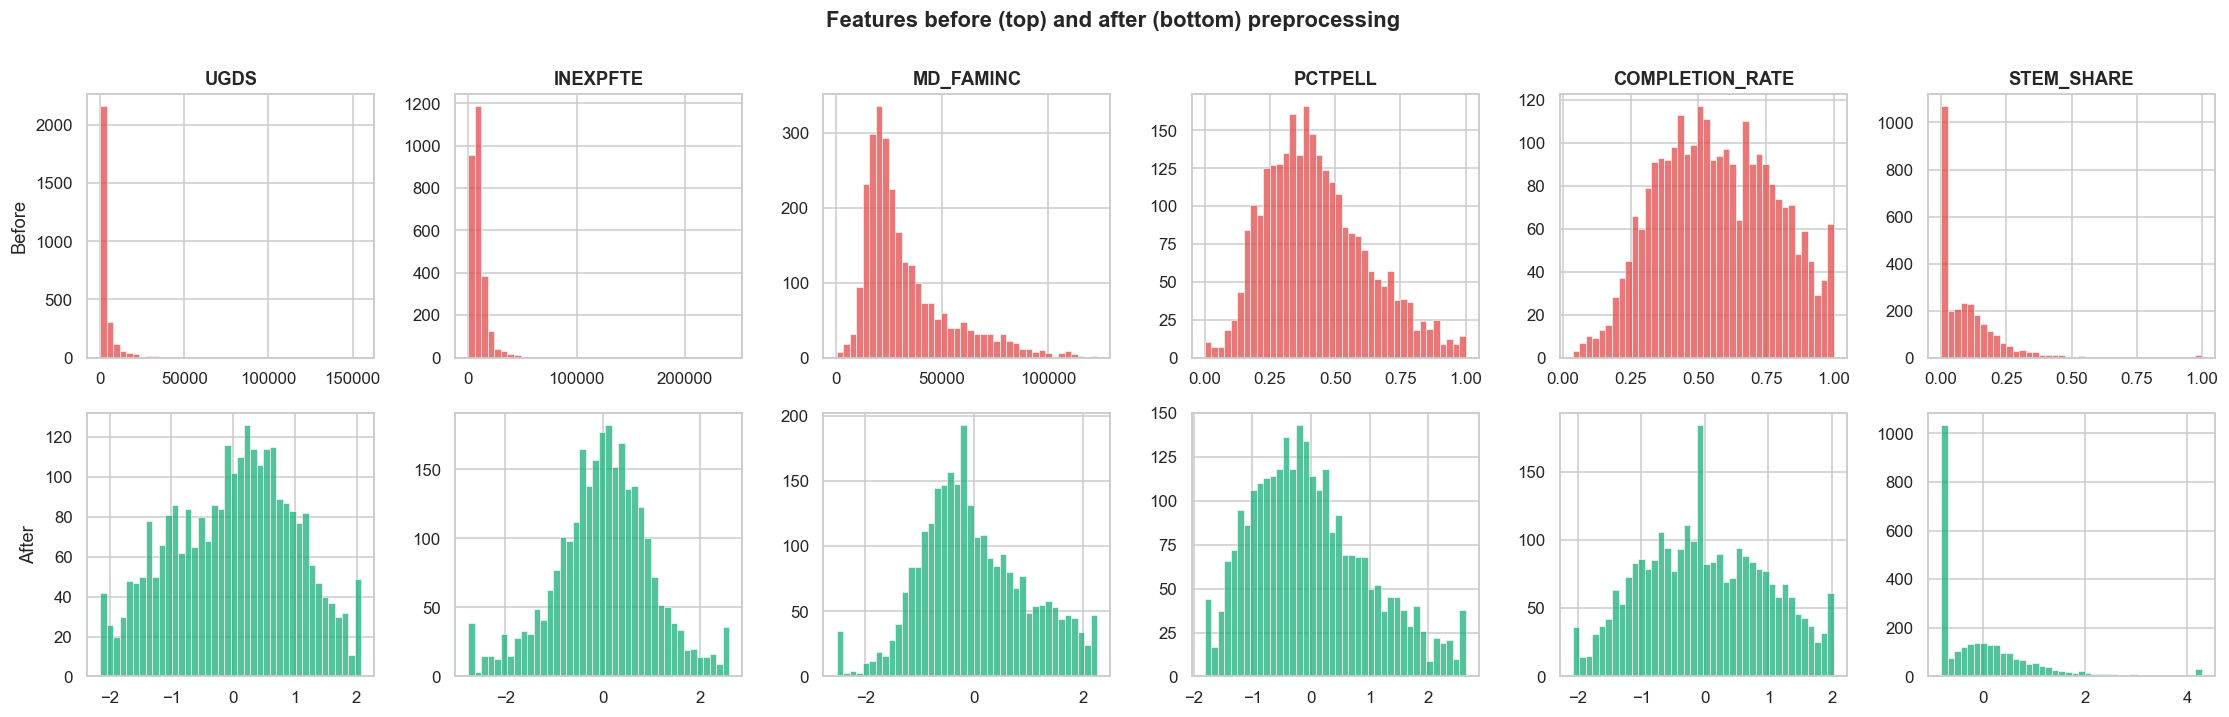

,mean before,std before,skew before,missing before,mean after,std after,skew after,missing after
UGDS,"3,350.952","7,077.656",7.124,4,0.000,0.999,-0.118,0
INEXPFTE,"9,977.612","10,743.190",8.624,1,0.000,1.000,-0.170,0
MD_FAMINC,"32,668.051","20,541.057",1.512,47,-0.002,0.992,0.238,0
PCTPELL,0.429,0.195,0.558,5,-0.000,0.999,0.554,0
COMPLETION_RATE,0.568,0.213,0.061,98,-0.002,0.982,0.089,0
STEM_SHARE,0.098,0.129,2.762,5,-0.000,0.999,1.785,0


In [ ]:
show = [c for c in ["UGDS", "INEXPFTE", "MD_FAMINC", "PCTPELL", "COMPLETION_RATE", "STEM_SHARE"] if c in NUMERIC_FEATURES]
fig, axes = plt.subplots(2, len(show), figsize=(3.4 * len(show), 6.5))
for j, col in enumerate(show):
    sns.histplot(X_train[col].dropna(), bins=40, ax=axes[0, j], color="#e34a4a")
    axes[0, j].set(title=col, xlabel="", ylabel="Before" if j == 0 else "")
    sns.histplot(Xt_train[col], bins=40, ax=axes[1, j], color="#1baf7a")
    axes[1, j].set(xlabel="", ylabel="After" if j == 0 else "")
plt.suptitle("Features before (top) and after (bottom) preprocessing", y=1.0, fontweight="bold")
plt.tight_layout(); save_fig("prep_before_after"); plt.show()

pd.DataFrame({"mean before": X_train[show].mean(), "std before": X_train[show].std(),
              "skew before": X_train[show].skew(), "missing before": X_train[show].isna().sum(),
              "mean after": Xt_train[show].mean(), "std after": Xt_train[show].std(),
              "skew after": Xt_train[show].skew(), "missing after": Xt_train[show].isna().sum()}).round(3)

In [ ]:
# Snapshots used by the Streamlit app (data overview and preprocessing inspector)
raw.to_csv(DATA_PROCESSED / "raw_subset.csv", index=False)
model_table.assign(SPLIT=np.select([model_table.index.isin(X_train.index), model_table.index.isin(X_val.index)],
                                   ["train", "validation"], default="test")
                   ).to_csv(DATA_PROCESSED / "model_table.csv", index=False)
Xt_train.to_csv(DATA_PROCESSED / "train_preprocessed_sample.csv", index=False)
print("Saved:", sorted(p.name for p in DATA_PROCESSED.glob("*.csv")))

Saved: ['model_table.csv', 'raw_subset.csv', 'train_preprocessed_sample.csv']


## 4. Model Training and Hyperparameter Tuning
Four algorithms with **different inductive biases** are compared, plus a trivial baseline:

| Model | Family | Assumption about the data |
|---|---|---|
| Baseline | predicts the training median for everyone | none: the score to beat |
| **ElasticNet** | regularised linear model | log-earnings are an additive, linear function of the features |
| **Random Forest** | bagging of deep decision trees | piecewise-constant function with interactions; variance reduced by averaging |
| **Histogram Gradient Boosting** | boosting of shallow trees | additive sequence of small corrections; bias reduced step by step |
| **Support Vector Regression (RBF)** | kernel method | smooth function; similar institutions have similar earnings |

**Target transform.** Every model is wrapped in `TransformedTargetRegressor`, which fits on `log(earnings)` and
converts predictions back to dollars, so all scores are in dollars.

**Tuning.** 5-fold cross-validation on the training set only. Grid search is used for ElasticNet (two
hyperparameters, a full grid is cheap); randomised search for the others (larger spaces, where random search finds
good regions with far fewer fits). The selection metric is **RMSE in dollars**; MAE and R² are recorded as well.

In [ ]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"}


def make_model(estimator):
    """Preprocessing + estimator, trained on log(earnings) and predicting dollars."""
    pipeline = Pipeline([("prep", make_preprocessor()), ("model", estimator)])
    return TransformedTargetRegressor(regressor=pipeline, func=np.log, inverse_func=np.exp)


P = "regressor__model__"          # prefix that reaches the estimator's hyperparameters

SEARCHES = {
    "ElasticNet": GridSearchCV(
        make_model(ElasticNet(max_iter=50_000, random_state=RANDOM_STATE)),
        param_grid={P + "alpha": np.logspace(-5, 0, 11), P + "l1_ratio": [0.05, 0.2, 0.5, 0.8, 1.0]},
        scoring=SCORING, refit="rmse", cv=cv, n_jobs=-1, return_train_score=True),

    "Random Forest": RandomizedSearchCV(
        make_model(RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1)),
        param_distributions={P + "n_estimators": [300, 500],
                             P + "max_depth": [None, 8, 12, 16, 24],
                             P + "min_samples_leaf": [1, 2, 4, 8],
                             P + "max_features": [0.2, 0.33, 0.5, "sqrt", 1.0]},
        n_iter=25, scoring=SCORING, refit="rmse", cv=cv, n_jobs=-1, random_state=RANDOM_STATE,
        return_train_score=True),

    "Hist Gradient Boosting": RandomizedSearchCV(
        make_model(HistGradientBoostingRegressor(random_state=RANDOM_STATE)),
        param_distributions={P + "learning_rate": loguniform(0.01, 0.3),
                             P + "max_iter": randint(150, 800),
                             P + "max_leaf_nodes": [8, 15, 31, 63],
                             P + "min_samples_leaf": [5, 10, 20, 40],
                             P + "l2_regularization": loguniform(1e-3, 10),
                             P + "max_features": [0.5, 0.8, 1.0]},
        n_iter=40, scoring=SCORING, refit="rmse", cv=cv, n_jobs=-1, random_state=RANDOM_STATE,
        return_train_score=True),

    "SVR (RBF)": RandomizedSearchCV(
        make_model(SVR(kernel="rbf")),
        param_distributions={P + "C": loguniform(0.1, 100),
                             P + "gamma": loguniform(1e-4, 1e-1),
                             P + "epsilon": uniform(0.01, 0.19)},
        n_iter=40, scoring=SCORING, refit="rmse", cv=cv, n_jobs=-1, random_state=RANDOM_STATE,
        return_train_score=True),
}

In [ ]:
fitted, cv_rows, cv_tables = {}, [], {}

baseline = DummyRegressor(strategy="median").fit(X_train, y_train)
fitted["Baseline (median)"] = baseline

for name, search in SEARCHES.items():
    start = time.time()
    search.fit(X_train, y_train)
    elapsed = time.time() - start
    fitted[name] = search.best_estimator_

    res = pd.DataFrame(search.cv_results_)
    cv_tables[name] = res
    res.drop(columns=[c for c in res.columns if c.startswith("split")]).to_csv(
        REPORTS_DIR / f"cv_results_{name.lower().replace(' ', '_').replace('(', '').replace(')', '')}.csv", index=False)

    best = res.loc[search.best_index_]
    cv_rows.append({"model": name, "candidates": len(res), "fits": len(res) * cv.get_n_splits(),
                    "cv_RMSE": -best["mean_test_rmse"], "cv_RMSE_std": best["std_test_rmse"],
                    "cv_MAE": -best["mean_test_mae"], "cv_R2": best["mean_test_r2"],
                    "train_RMSE_in_cv": -best["mean_train_rmse"], "search_time_s": elapsed,
                    "best_params": {k.replace(P, ""): (round(float(v), 5) if isinstance(v, float) else
                                                       int(v) if isinstance(v, (int, np.integer)) else v)
                                    for k, v in search.best_params_.items()}})
    print(f"{name:<24} CV RMSE ${-best['mean_test_rmse']:>8,.0f} ± {best['std_test_rmse']:>5,.0f}   "
          f"R² {best['mean_test_r2']:.3f}   ({len(res)} candidates, {elapsed:.0f}s)")

cv_summary = pd.DataFrame(cv_rows).set_index("model")
cv_summary.to_csv(REPORTS_DIR / "cv_summary.csv")
with pd.option_context("display.max_colwidth", None):
    display(cv_summary)

ElasticNet               CV RMSE $   7,716 ±   797   R² 0.808   (55 candidates, 10s)


Random Forest            CV RMSE $   7,315 ±   764   R² 0.827   (25 candidates, 83s)


Hist Gradient Boosting   CV RMSE $   6,812 ±   711   R² 0.850   (40 candidates, 78s)


SVR (RBF)                CV RMSE $   6,825 ±   759   R² 0.849   (40 candidates, 12s)


,candidates,fits,cv_RMSE,cv_RMSE_std,cv_MAE,cv_R2,train_RMSE_in_cv,search_time_s,best_params
model,,,,,,,,,
ElasticNet,55,275,"7,715.833",797.317,"4,998.304",0.808,"7,341.514",9.811,"{'alpha': 3e-05, 'l1_ratio': 1.0}"
Random Forest,25,125,"7,314.675",763.577,"4,514.781",0.827,"2,956.383",82.985,"{'n_estimators': 500, 'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': 24}"
Hist Gradient Boosting,40,200,"6,812.333",710.527,"4,294.856",0.850,"1,249.892",77.522,"{'l2_regularization': 1.21302, 'learning_rate': 0.05363, 'max_features': 0.5, 'max_iter': 356, 'max_leaf_nodes': 31, 'min_samples_leaf': 10}"
SVR (RBF),40,200,"6,825.118",759.150,"4,314.323",0.849,"4,315.338",12.122,"{'C': 9.71778, 'epsilon': 0.06923, 'gamma': 0.00363}"


### 4.1 How sensitive is each model to its hyperparameters?
Each point is one hyperparameter configuration tried during the search. A flat cloud means the model is robust to
that hyperparameter; a clear trend shows where the good region is and whether the search range covered it.

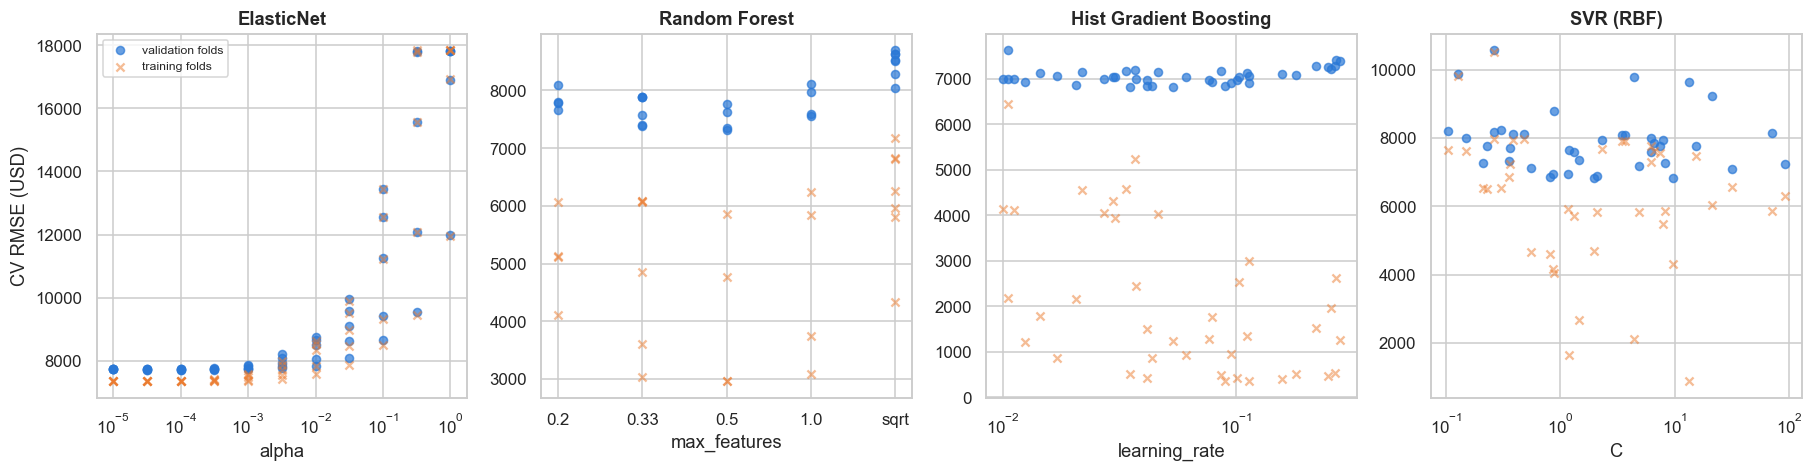

In [ ]:
main_param = {"ElasticNet": ("alpha", True), "Random Forest": ("max_features", False),
              "Hist Gradient Boosting": ("learning_rate", True), "SVR (RBF)": ("C", True)}
fig, axes = plt.subplots(1, 4, figsize=(20, 4.3))
for ax, (name, (param, logx)) in zip(axes, main_param.items()):
    res = cv_tables[name]
    xs = res["param_" + P + param]
    xs = xs.astype(float) if logx else xs.astype(str)
    order = np.argsort(xs.to_numpy(), kind="stable")              # keeps categorical axes in a sensible order
    xs, rmse_valid, rmse_train = xs.iloc[order], -res["mean_test_rmse"].iloc[order], -res["mean_train_rmse"].iloc[order]
    ax.scatter(xs, rmse_valid, s=28, alpha=0.7, color="#2a78d6", label="validation folds")
    ax.scatter(xs, rmse_train, s=28, alpha=0.5, color="#eb7a2d", marker="x", label="training folds")
    if logx:
        ax.set_xscale("log")
    ax.set(title=name, xlabel=param, ylabel="CV RMSE (USD)" if ax is axes[0] else "")
axes[0].legend(fontsize=8)
save_fig("tuning_sensitivity"); plt.show()

## 5. Model Evaluation
### 5.1 Metrics
| Metric | Meaning | Why it is used here |
|---|---|---|
| **RMSE** | root mean squared error, in dollars | Penalises large misses most. A big error on one college is worse than several small ones |
| **MAE** | mean absolute error, in dollars | The typical miss, easy to explain; less sensitive to the few very high earners |
| **MedAE** | median absolute error | The miss for the "typical" institution, unaffected by outliers |
| **MAPE** | mean absolute percentage error | Scale-free: a \$5,000 error matters more at \$25,000 than at \$100,000. Safe here because earnings are never near zero |
| **R²** | share of variance explained | Compares with the baseline (R² ≈ 0) |

The **validation** set is used to choose the model; the **test** set is used once to report its performance.

In [ ]:
def regression_metrics(y_true, y_pred):
    return {"RMSE": root_mean_squared_error(y_true, y_pred),
            "MAE": mean_absolute_error(y_true, y_pred),
            "MedAE": median_absolute_error(y_true, y_pred),
            "MAPE_%": mean_absolute_percentage_error(y_true, y_pred) * 100,
            "R2": r2_score(y_true, y_pred)}


preds = {split: {name: model.predict(Xs) for name, model in fitted.items()}
         for split, Xs in [("train", X_train), ("validation", X_val), ("test", X_test)]}
truth = {"train": y_train, "validation": y_val, "test": y_test}
assert all(np.isfinite(p).all() and (p > 0).all() for d in preds.values() for p in d.values())

results = pd.concat({split: pd.DataFrame({name: regression_metrics(truth[split], p) for name, p in d.items()}).T
                     for split, d in preds.items()}, axis=1)
results.to_csv(REPORTS_DIR / "metrics_all_splits.csv")

print("VALIDATION set (used for model selection)")
display(results["validation"].sort_values("RMSE").style.format(
    {"RMSE": "${:,.0f}", "MAE": "${:,.0f}", "MedAE": "${:,.0f}", "MAPE_%": "{:.2f}", "R2": "{:.4f}"}))

VALIDATION set (used for model selection)


,RMSE,MAE,MedAE,MAPE_%,R2
SVR (RBF),"$5,383","$3,709","$2,471",8.05,0.9014
Hist Gradient Boosting,"$5,972","$3,977","$2,730",8.54,0.8786
Random Forest,"$6,422","$4,235","$2,713",8.91,0.8596
ElasticNet,"$6,446","$4,585","$3,127",9.86,0.8585
Baseline (median),"$17,364","$12,976","$10,139",28.22,-0.0264


In [ ]:
candidates = [m for m in fitted if not m.startswith("Baseline")]
best_name = results["validation"].loc[candidates, "RMSE"].idxmin()
runner_up = results["validation"].loc[candidates, "RMSE"].sort_values().index[1]
print(f"Selected on the validation set: {best_name}  (runner-up: {runner_up})\n")

test_tbl = results["test"].sort_values("RMSE").copy()
base_rmse = test_tbl.loc["Baseline (median)", "RMSE"]
test_tbl["RMSE vs baseline"] = (test_tbl["RMSE"] / base_rmse - 1) * 100
test_tbl.to_csv(REPORTS_DIR / "metrics_test.csv")

print("HELD-OUT TEST set (final comparison)")
display(test_tbl.style.format({"RMSE": "${:,.0f}", "MAE": "${:,.0f}", "MedAE": "${:,.0f}", "MAPE_%": "{:.2f}",
                               "R2": "{:.4f}", "RMSE vs baseline": "{:+.1f}%"})
        .highlight_min(subset=["RMSE", "MAE", "MedAE", "MAPE_%"], color="#c8ecd9")
        .highlight_max(subset=["R2"], color="#c8ecd9"))

Selected on the validation set: SVR (RBF)  (runner-up: Hist Gradient Boosting)

HELD-OUT TEST set (final comparison)


,RMSE,MAE,MedAE,MAPE_%,R2,RMSE vs baseline
SVR (RBF),"$6,360","$3,972","$2,556",8.07,0.8880,-67.0%
Hist Gradient Boosting,"$6,516","$4,098","$2,698",8.17,0.8824,-66.2%
Random Forest,"$6,886","$4,303","$2,612",8.56,0.8687,-64.3%
ElasticNet,"$7,969","$5,140","$3,505",10.28,0.8242,-58.7%
Baseline (median),"$19,301","$13,695","$10,148",28.73,-0.0315,+0.0%


**Reading the tables.** Every model removes roughly 59 – 67 % of the baseline's error, so institutional
characteristics carry a lot of information about earnings. The three non-linear models beat the linear one, as the
EDA suggested (curved relationships, and features such as completion rate that only matter in combination with
others). **SVR (RBF)** has the lowest validation RMSE and is selected; on the test set it explains about 89 % of the
variance, with a typical error of about \$4,000 (8 % of earnings).

### 5.2 Generalisation: train vs. cross-validation vs. validation vs. test
A large gap between the training score and the others means overfitting. Similar CV, validation and test scores
mean the estimate of performance is stable.

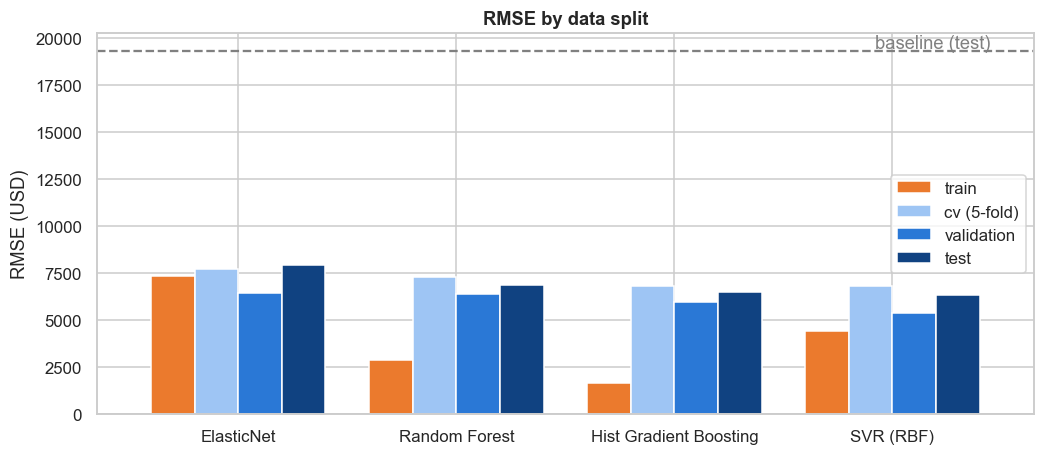

,train,cv (5-fold),validation,test,train/test ratio
ElasticNet,"7,384.911","7,715.833","6,446.448","7,968.672",0.927
Random Forest,"2,896.118","7,314.675","6,421.529","6,886.321",0.421
Hist Gradient Boosting,"1,681.295","6,812.333","5,971.631","6,516.166",0.258
SVR (RBF),"4,421.122","6,825.118","5,382.892","6,360.372",0.695


In [ ]:
gap = pd.DataFrame({"train": results["train"]["RMSE"], "cv (5-fold)": cv_summary["cv_RMSE"],
                    "validation": results["validation"]["RMSE"], "test": results["test"]["RMSE"]}).loc[candidates]
gap["train/test ratio"] = gap["train"] / gap["test"]

ax = gap.drop(columns="train/test ratio").plot.bar(figsize=(11, 4.5), rot=0, width=0.8,
                                                    color=["#eb7a2d", "#9ec5f4", "#2a78d6", "#104281"])
ax.axhline(base_rmse, ls="--", c="grey"); ax.text(3.45, base_rmse * 1.01, "baseline (test)", ha="right", color="grey")
ax.set(title="RMSE by data split", ylabel="RMSE (USD)", xlabel="")
save_fig("eval_rmse_by_split"); plt.show()
gap.round(3)

**Reading the chart.**
* **ElasticNet** has nearly the same error on training and test data: it is not overfitting, it is *underfitting*
  (high bias). A straight-line model cannot represent the interactions in the data.
* **Random Forest and Gradient Boosting** fit the training set almost perfectly and are two to four times worse on
  unseen data. That gap is typical of flexible tree ensembles; what matters is that their cross-validated and test
  errors are still lower than the linear model's.
* **SVR** has the smallest gap among the non-linear models and the lowest test error.
* Validation errors are lower than cross-validation and test errors for *every* model. The validation sample
  happens to contain no institution above about \$110,000 (Section 3.4), and the highest earners are the hardest
  to predict. It affects all models alike, so the ranking is still valid, but the cross-validation and test figures
  are the realistic estimates of performance.

### 5.3 Is the difference between models real? (uncertainty)
The test set is small, so each score has sampling error. A **bootstrap** (2,000 resamples of the test set) gives a
95 % confidence interval for every model, and a **paired Wilcoxon signed-rank test** checks whether the best model's
absolute errors are systematically smaller than the runner-up's on the same institutions.

SVR (RBF) vs Hist Gradient Boosting on the test set
  RMSE difference (runner-up minus best): $151  95% CI [$-193, $470]
  Wilcoxon signed-rank on absolute errors: W = 83,671, p = 0.2091


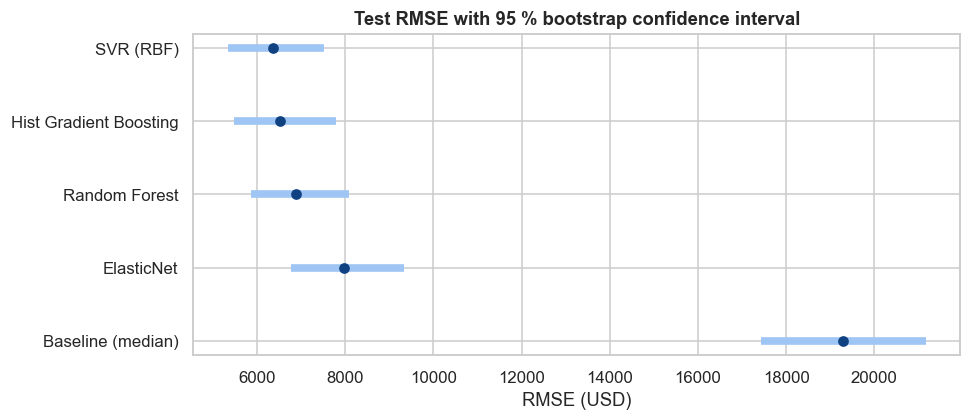

,RMSE,RMSE_lo,RMSE_hi,R2,R2_lo,R2_hi
SVR (RBF),"6,360.372","5,339.387","7,525.714",0.888,0.848,0.918
Hist Gradient Boosting,"6,516.166","5,482.850","7,798.449",0.882,0.837,0.912
Random Forest,"6,886.321","5,860.234","8,079.012",0.869,0.828,0.898
ElasticNet,"7,968.672","6,771.087","9,323.273",0.824,0.768,0.866
Baseline (median),"19,300.592","17,430.123","21,161.161",-0.031,-0.062,-0.011


In [ ]:
rng = np.random.default_rng(RANDOM_STATE)
boot_idx = rng.integers(0, len(y_test), size=(2000, len(y_test)))
y_te = y_test.to_numpy()

ci_rows = {}
for name, p in preds["test"].items():
    rmse_b = np.sqrt(((y_te[boot_idx] - p[boot_idx]) ** 2).mean(axis=1))
    r2_b = 1 - ((y_te[boot_idx] - p[boot_idx]) ** 2).sum(axis=1) / \
               ((y_te[boot_idx] - y_te[boot_idx].mean(axis=1, keepdims=True)) ** 2).sum(axis=1)
    ci_rows[name] = {"RMSE": results["test"].loc[name, "RMSE"], "RMSE_lo": np.percentile(rmse_b, 2.5),
                     "RMSE_hi": np.percentile(rmse_b, 97.5), "R2": results["test"].loc[name, "R2"],
                     "R2_lo": np.percentile(r2_b, 2.5), "R2_hi": np.percentile(r2_b, 97.5)}
ci = pd.DataFrame(ci_rows).T.sort_values("RMSE")
ci.to_csv(REPORTS_DIR / "metrics_test_bootstrap_ci.csv")

err_best = np.abs(y_te - preds["test"][best_name]); err_second = np.abs(y_te - preds["test"][runner_up])
w_stat, w_p = stats.wilcoxon(err_best, err_second)
diff_b = np.sqrt(((y_te[boot_idx] - preds["test"][runner_up][boot_idx]) ** 2).mean(axis=1)) - \
         np.sqrt(((y_te[boot_idx] - preds["test"][best_name][boot_idx]) ** 2).mean(axis=1))
print(f"{best_name} vs {runner_up} on the test set")
print(f"  RMSE difference (runner-up minus best): ${diff_b.mean():,.0f}  "
      f"95% CI [${np.percentile(diff_b, 2.5):,.0f}, ${np.percentile(diff_b, 97.5):,.0f}]")
print(f"  Wilcoxon signed-rank on absolute errors: W = {w_stat:,.0f}, p = {w_p:.4f}")

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.errorbar(ci["RMSE"], ci.index, xerr=[ci["RMSE"] - ci["RMSE_lo"], ci["RMSE_hi"] - ci["RMSE"]],
            fmt="o", color="#104281", ecolor="#9ec5f4", elinewidth=5, capsize=0)
ax.invert_yaxis(); ax.set(title="Test RMSE with 95 % bootstrap confidence interval", xlabel="RMSE (USD)")
save_fig("eval_bootstrap_ci"); plt.show()
ci.round(3)

**Reading the result.** The confidence intervals of SVR and Gradient Boosting overlap almost completely, the
interval for their RMSE difference includes zero, and the Wilcoxon test does not reject equality. On this test set
the two models are **statistically indistinguishable**. SVR is kept as the final model because it was chosen on the
validation set *before* the test set was opened (changing the choice after seeing test results would bias the
reported score), it has the smaller train–test gap, and its file is small. The honest claim is "SVR and Gradient
Boosting are equally good, and both are clearly better than ElasticNet", not "SVR is the best".

### 5.4 Predicted vs. actual, and residual plots
For a regression problem these play the role that ROC curves and confusion matrices play in classification. A good
model has points along the diagonal, and residuals that are centred on zero with no pattern.

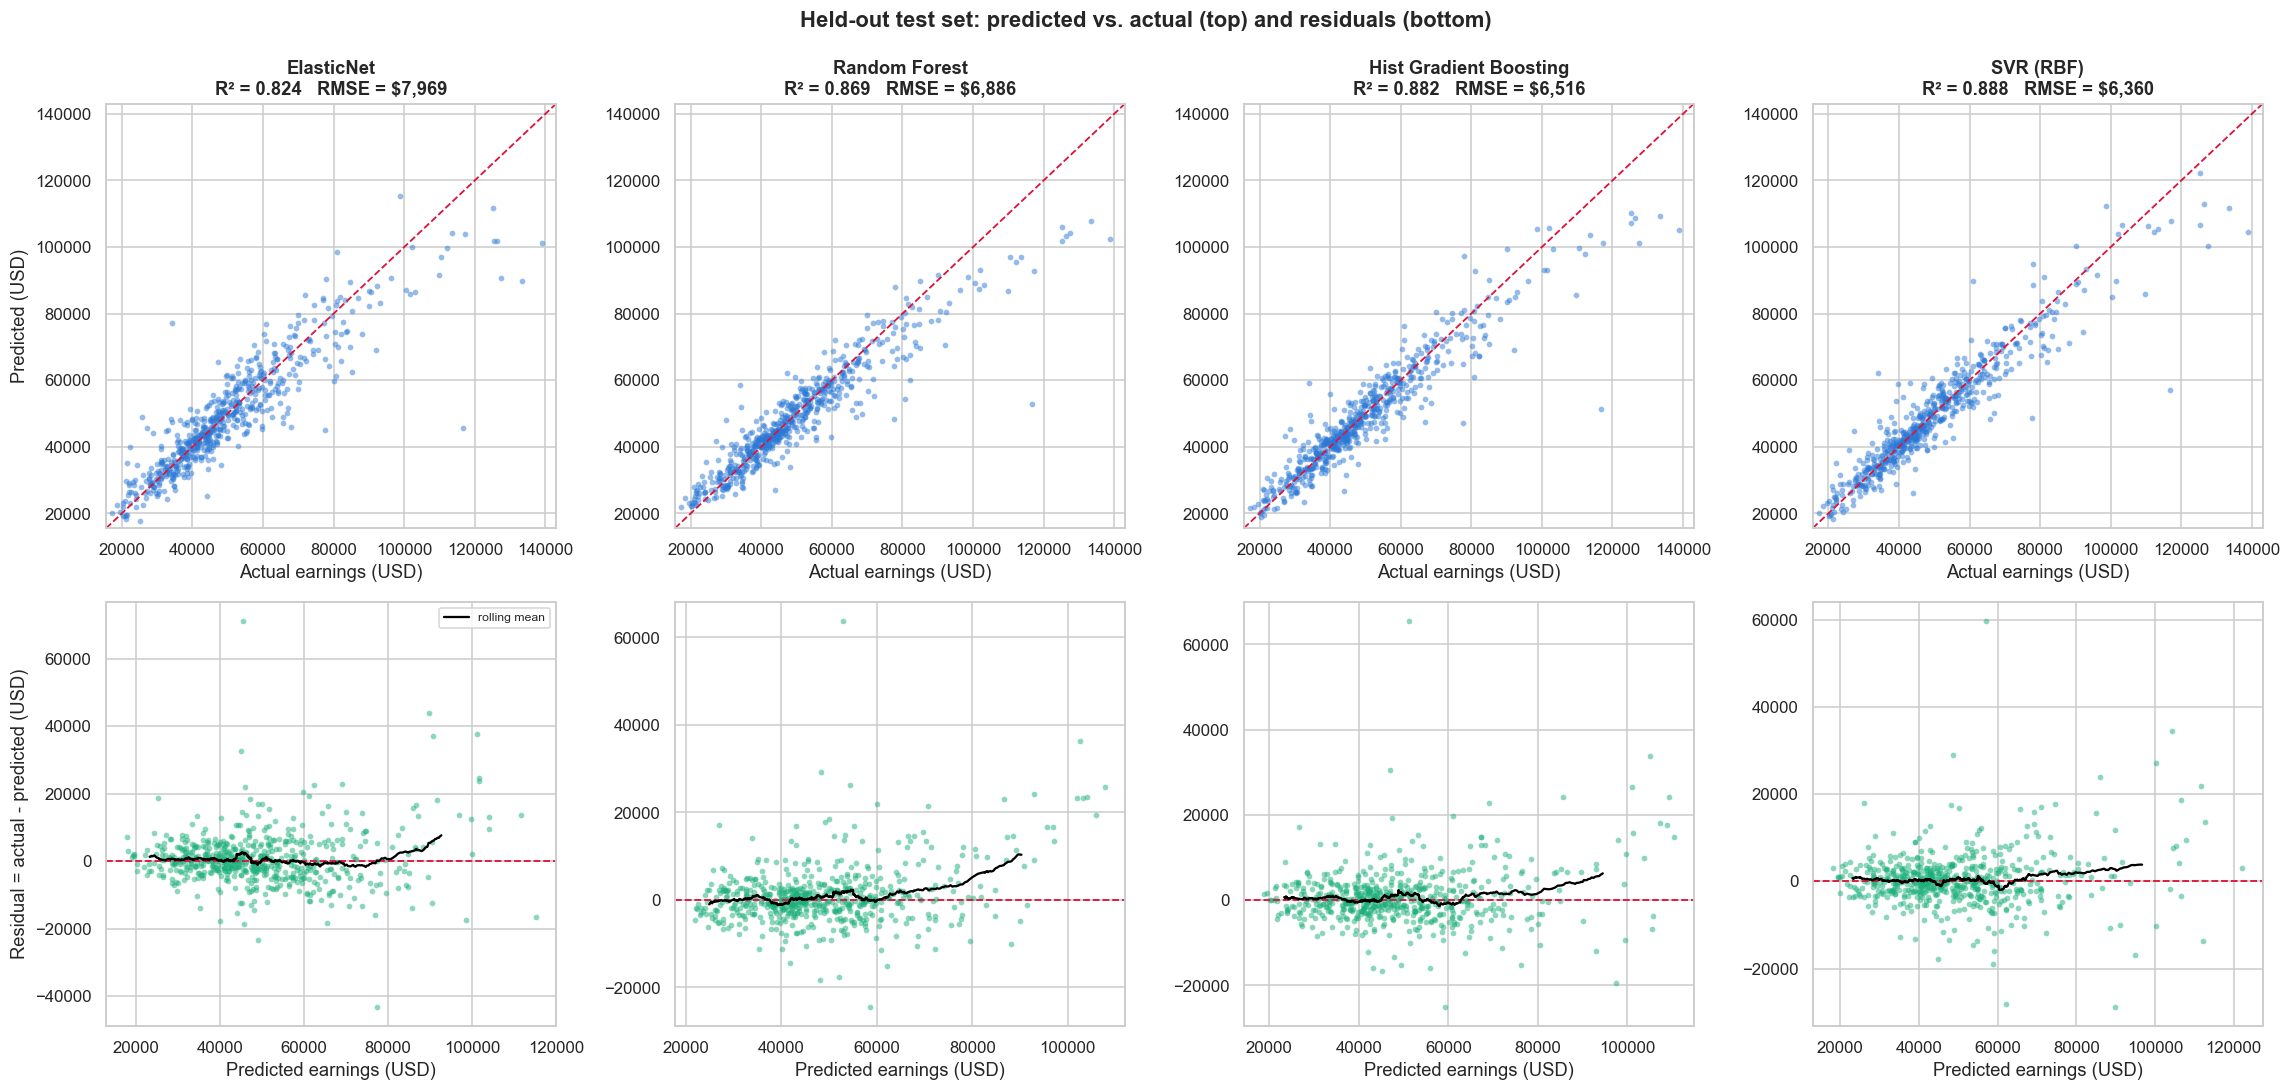

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(21, 10))
lims = [y_test.min() * 0.9, y_test.max() * 1.03]
for j, name in enumerate(candidates):
    p = preds["test"][name]; resid = y_test - p
    ax = axes[0, j]
    ax.scatter(y_test, p, s=14, alpha=0.5, color="#2a78d6", linewidth=0)
    ax.plot(lims, lims, "--", c="crimson", lw=1.2)
    ax.set(title=f"{name}\nR² = {results['test'].loc[name, 'R2']:.3f}   RMSE = ${results['test'].loc[name, 'RMSE']:,.0f}",
           xlabel="Actual earnings (USD)", ylabel="Predicted (USD)" if j == 0 else "", xlim=lims, ylim=lims)
    ax = axes[1, j]
    ax.scatter(p, resid, s=14, alpha=0.5, color="#1baf7a", linewidth=0)
    ax.axhline(0, ls="--", c="crimson", lw=1.2)
    smooth = pd.DataFrame({"p": p, "r": resid.values}).sort_values("p").rolling(60, center=True, min_periods=20).mean()
    ax.plot(smooth["p"], smooth["r"], c="black", lw=1.5, label="rolling mean")
    ax.set(xlabel="Predicted earnings (USD)", ylabel="Residual = actual - predicted (USD)" if j == 0 else "")
    if j == 0:
        ax.legend(fontsize=8)
plt.suptitle("Held-out test set: predicted vs. actual (top) and residuals (bottom)", y=0.99, fontweight="bold")
plt.tight_layout(); save_fig("eval_pred_vs_actual_residuals"); plt.show()

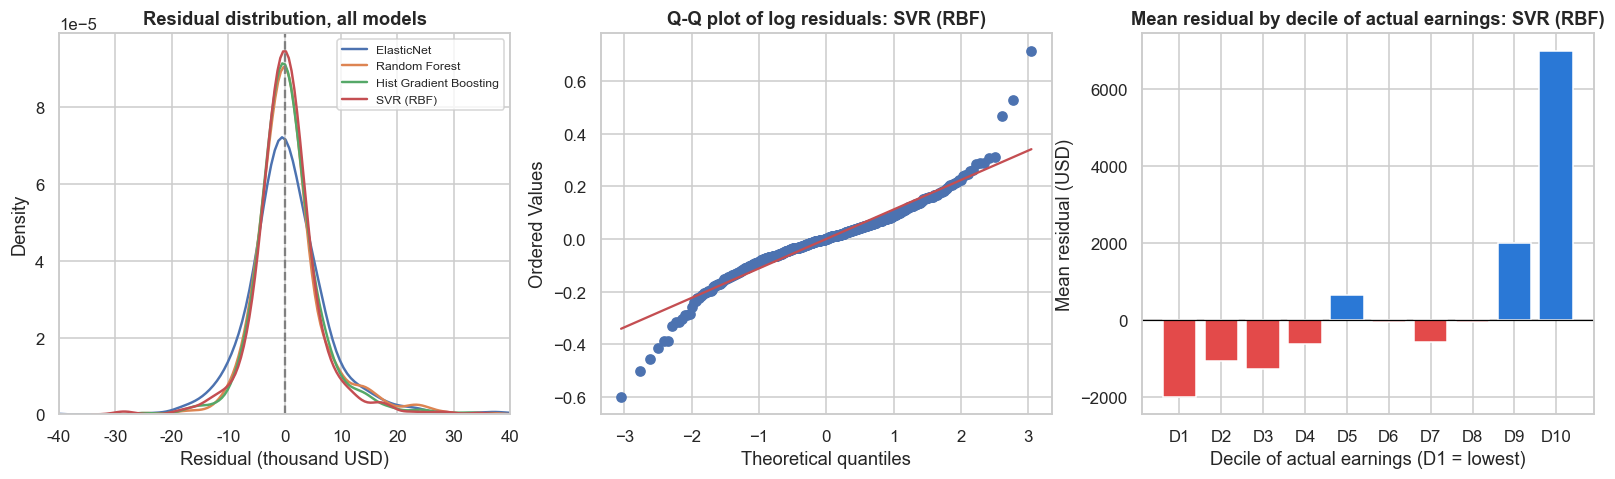

SVR (RBF): mean residual $398, median $-28, within ±10 % of actual for 72.7% of test institutions, within ±20 % for 93.1%.


In [ ]:
resid_best = y_test - preds["test"][best_name]
log_resid = np.log(y_test) - np.log(preds["test"][best_name])

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for name in candidates:
    sns.kdeplot(y_test - preds["test"][name], ax=axes[0], label=name, lw=1.6)
axes[0].axvline(0, c="grey", ls="--"); axes[0].legend(fontsize=8)
axes[0].set(title="Residual distribution, all models", xlabel="Residual (thousand USD)", xlim=(-40_000, 40_000))
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1000:.0f}"))

stats.probplot(log_resid, dist="norm", plot=axes[1]); axes[1].set_title(f"Q-Q plot of log residuals: {best_name}")

decile = pd.qcut(y_test, 10, labels=[f"D{i}" for i in range(1, 11)])
bias = resid_best.groupby(decile, observed=True).mean()
axes[2].bar(bias.index.astype(str), bias.values, color=np.where(bias.values < 0, "#e34a4a", "#2a78d6"))
axes[2].axhline(0, c="black", lw=0.8)
axes[2].set(title=f"Mean residual by decile of actual earnings: {best_name}",
            xlabel="Decile of actual earnings (D1 = lowest)", ylabel="Mean residual (USD)")
save_fig("eval_residual_diagnostics"); plt.show()

print(f"{best_name}: mean residual ${resid_best.mean():,.0f}, median ${resid_best.median():,.0f}, "
      f"within ±10 % of actual for {(np.abs(resid_best) / y_test <= 0.10).mean():.1%} of test institutions, "
      f"within ±20 % for {(np.abs(resid_best) / y_test <= 0.20).mean():.1%}.")

**Reading the plots.** Predictions follow the diagonal closely up to about \$80,000. Above that, every model
**under-predicts**: the points fall below the diagonal and the residuals of the top decile are large and positive.
There are three reasons: very few training institutions have such earnings; the models are trained on log earnings
and so predict a typical (geometric-mean) value rather than an extreme one; and what makes these colleges exceptional
(for example, a pipeline into finance or technology employers) is not among the features. The log residuals are
close to normal in the centre with heavier tails than a normal distribution.

### 5.5 Where does the best model make its errors? (slice analysis)
An overall score can hide groups for which the model is much worse. This matters ethically: a benchmark that is
systematically less accurate for one sector would treat that sector unfairly.

In [ ]:
test_frame = model_table.loc[X_test.index, ["INSTNM", "STABBR", "CONTROL", "PREDDEG", "COUNT_WNE_P10"]].copy()
test_frame["actual"] = y_test
for name in candidates:
    test_frame[f"pred_{name}"] = preds["test"][name]
test_frame["pred_best"] = preds["test"][best_name]
test_frame["residual"] = test_frame["actual"] - test_frame["pred_best"]
test_frame["abs_pct_error"] = test_frame["residual"].abs() / test_frame["actual"] * 100
test_frame.to_csv(REPORTS_DIR / "test_predictions.csv")


def slice_metrics(g):
    return pd.Series({"n": len(g), "RMSE": root_mean_squared_error(g["actual"], g["pred_best"]),
                      "MAE": mean_absolute_error(g["actual"], g["pred_best"]),
                      "MAPE_%": g["abs_pct_error"].mean(), "mean residual (bias)": g["residual"].mean()})


slices = pd.concat({col: test_frame.groupby(col)[["actual", "pred_best", "abs_pct_error", "residual"]].apply(slice_metrics)
                    for col in ["CONTROL", "PREDDEG"]})
slices.to_csv(REPORTS_DIR / "metrics_test_slices.csv")
display(slices.round(1))

print("Largest errors of the selected model on the test set:")
test_frame.reindex(test_frame["residual"].abs().sort_values(ascending=False).index).head(8)[
    ["INSTNM", "STABBR", "CONTROL", "PREDDEG", "actual", "pred_best", "residual"]].round(0)

n      RMSE       MAE  MAPE_%  \
CONTROL Private for-profit 157.000 7,385.300 4,189.800  11.400   
        Private nonprofit  180.000 7,767.100 5,414.100   8.600   
        Public             259.000 4,254.700 2,838.700   5.700   
PREDDEG Associate          108.000 3,899.200 2,739.400   5.800   
        Bachelor           241.000 7,104.300 4,805.400   7.600   
        Certificate        247.000 6,459.200 3,698.800   9.500   

                            mean residual (bias)  
CONTROL Private for-profit               -77.900  
        Private nonprofit              1,347.100  
        Public                            27.800  
PREDDEG Associate                        257.400  
        Bachelor                         915.400  
        Certificate                      -44.400

Largest errors of the selected model on the test set:


,INSTNM,STABBR,CONTROL,PREDDEG,actual,pred_best,residual
3615,Aviator College of Aeronautical Science and Te...,FL,Private for-profit,Certificate,"116,728.000","57,051.000","59,677.000"
685,Babson College,MA,Private nonprofit,Bachelor,"138,950.000","104,397.000","34,553.000"
3744,Touro University Worldwide,CA,Private nonprofit,Bachelor,"77,590.000","48,682.000","28,908.000"
3775,Homestead Schools,CA,Private nonprofit,Certificate,"60,911.000","89,749.000","-28,838.000"
3262,Midwest College of Oriental Medicine-Racine,WI,Private for-profit,Certificate,"34,086.000","62,150.000","-28,064.000"
112,Claremont McKenna College,CA,Private nonprofit,Bachelor,"127,532.000","100,322.000","27,210.000"
1838,Oregon Health & Science University,OR,Public,Bachelor,"109,788.000","85,926.000","23,862.000"
981,Princeton University,NJ,Private nonprofit,Bachelor,"133,523.000","111,591.000","21,932.000"


**Reading the slices.** The model is most accurate for public colleges and associate-degree colleges (MAPE under
6 %) and about twice as inaccurate, in relative terms, for private for-profit colleges, which are small and highly
specialised. For private non-profit colleges the mean residual is clearly positive: this is the under-prediction
of elite colleges seen above. The largest individual errors are institutions tied to a single occupation
(a flight school, health-science universities) or highly selective colleges. Any use of the model as a benchmark
should therefore report an uncertainty that depends on the sector, not one overall number.

### 5.6 What drives the predictions? (permutation importance)
Each feature is shuffled in turn on the validation set and the increase in RMSE is measured. This is
model-agnostic, is measured on data the model did not train on, and is expressed in dollars. Correlated features
share their importance, so a low value does not prove a feature is irrelevant.

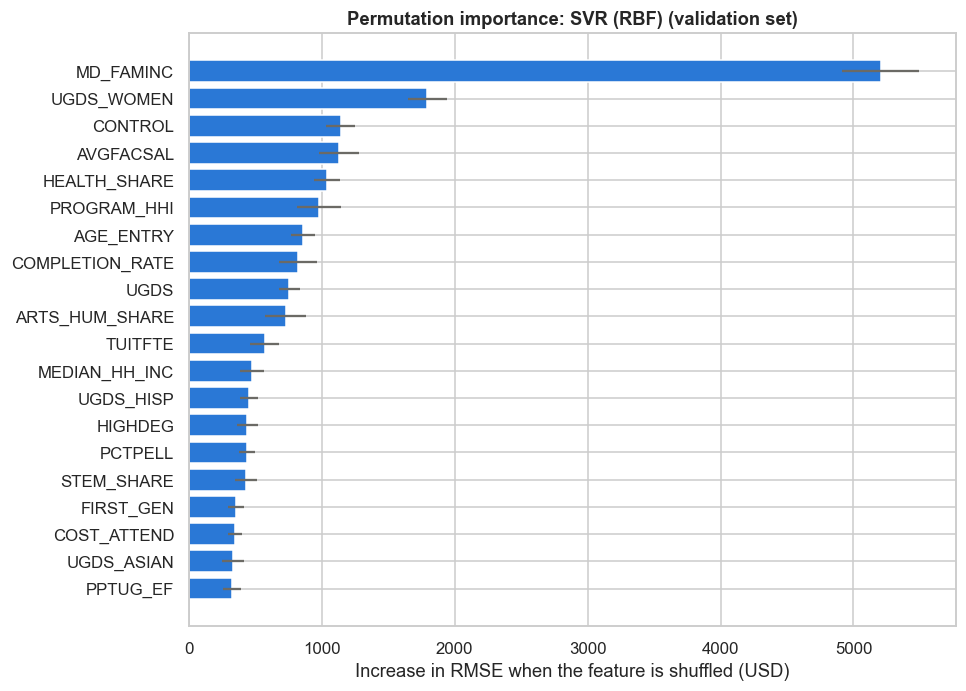

,feature,rmse_increase,std
0,MD_FAMINC,"5,205.300",290.200
1,UGDS_WOMEN,"1,796.200",146.100
2,CONTROL,"1,143.400",108.900
3,AVGFACSAL,"1,131.400",153.600
4,HEALTH_SHARE,"1,040.500",96.400
5,PROGRAM_HHI,980.400,165.300
6,AGE_ENTRY,859.600,88.600
7,COMPLETION_RATE,824.100,140.900
8,UGDS,756.800,77.400
9,ARTS_HUM_SHARE,729.900,153.800


In [ ]:
perm = permutation_importance(fitted[best_name], X_val, y_val, scoring="neg_root_mean_squared_error",
                              n_repeats=15, random_state=RANDOM_STATE, n_jobs=-1)
importance = (pd.DataFrame({"feature": FEATURES, "rmse_increase": perm.importances_mean,
                            "std": perm.importances_std})
              .sort_values("rmse_increase", ascending=False).reset_index(drop=True))
importance.to_csv(REPORTS_DIR / "permutation_importance.csv", index=False)

top = importance.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top["feature"], top["rmse_increase"], xerr=top["std"], color="#2a78d6", ecolor="#6b6a65")
ax.set(title=f"Permutation importance: {best_name} (validation set)",
       xlabel="Increase in RMSE when the feature is shuffled (USD)")
save_fig("eval_permutation_importance"); plt.show()
importance.head(12).round(1)

**Reading the chart.** The **family income of the students** a college enrols is by far the most important
feature: shuffling it adds almost three times as much error as shuffling the next feature. The **share of women** is
second, which reflects the gender pay gap and the fields women and men are concentrated in, not anything a college
does. Sector, faculty salary, programme mix and completion follow. The model therefore predicts earnings mostly
from *who enrols* and *what is taught*; it must not be read as a measure of teaching quality, and a high
prediction is not evidence that a college causes high earnings.

### 5.7 Learning curve of the selected model
Shows whether more data would help (validation curve still falling) or whether the model has reached the limit of
what these features can explain (curves flat and close together).

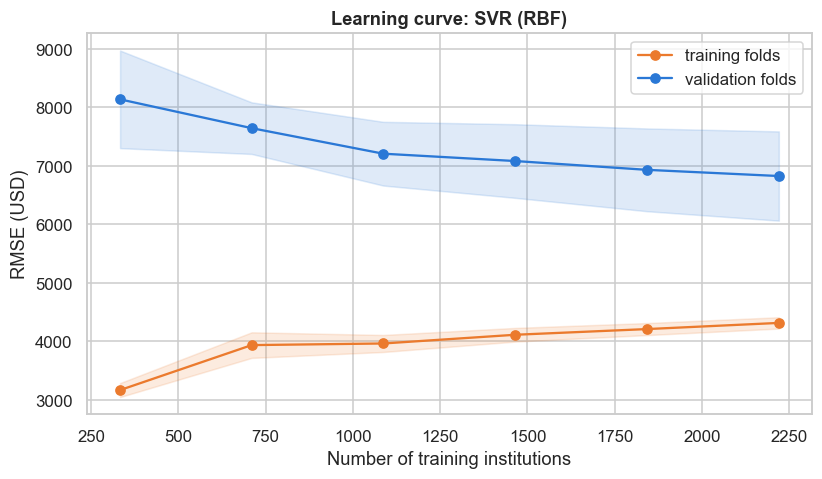

In [ ]:
sizes, train_scores, valid_scores = learning_curve(
    fitted[best_name], X_train, y_train, train_sizes=np.linspace(0.15, 1.0, 6), cv=cv,
    scoring="neg_root_mean_squared_error", n_jobs=-1)

fig, ax = plt.subplots(figsize=(8.5, 4.5))
for scores, label, color in [(train_scores, "training folds", "#eb7a2d"), (valid_scores, "validation folds", "#2a78d6")]:
    mean, std = -scores.mean(axis=1), scores.std(axis=1)
    ax.plot(sizes, mean, "o-", color=color, label=label)
    ax.fill_between(sizes, mean - std, mean + std, color=color, alpha=0.15)
ax.set(title=f"Learning curve: {best_name}", xlabel="Number of training institutions", ylabel="RMSE (USD)")
ax.legend(); save_fig("eval_learning_curve"); plt.show()

**Reading the chart.** The validation curve is still falling slowly at the full training size and the gap to the
training curve is still wide. More institutions would help a little, but the number of U.S. colleges is fixed, so
further gains have to come from better features (for example programme-level earnings) rather than more rows.

## 6. Export of Models and Artefacts
1. Every tuned model is saved exactly as it was evaluated (each file contains preprocessing **and** estimator).
2. The selected configuration is refitted on **train + validation** and saved as `final_model.joblib` for the app.
   The hyperparameters are not re-tuned, so the test set remains an honest check of this final model.
3. `metadata.json` stores what the app needs to build its input form and to document the run.

In [ ]:
from sklearn.base import clone

final_model = clone(fitted[best_name]).fit(pd.concat([X_train, X_val]), pd.concat([y_train, y_val]))
final_test_metrics = regression_metrics(y_test, final_model.predict(X_test))

print(f"Final model: {best_name}, refitted on train + validation ({len(X_train) + len(X_val):,} institutions)")
pd.DataFrame({"trained on train only": results["test"].loc[best_name],
              "refitted on train + validation": final_test_metrics}).T.round(4)

Final model: SVR (RBF), refitted on train + validation (3,371 institutions)


,RMSE,MAE,MedAE,MAPE_%,R2
trained on train only,"6,360.372","3,972.421","2,555.727",8.073,0.888
refitted on train + validation,"6,434.547","4,006.563","2,485.753",8.136,0.885


In [ ]:
def slug(name):
    return name.lower().replace(" ", "_").replace("(", "").replace(")", "")


for name, model in fitted.items():
    joblib.dump(model, MODELS_DIR / f"{slug(name)}.joblib", compress=3)
joblib.dump(final_model, MODELS_DIR / "final_model.joblib", compress=3)

X_fit = pd.concat([X_train, X_val])
FEATURE_LABELS = {
    "UGDS": "Undergraduate enrolment", "NUMBRANCH": "Number of campuses", "PPTUG_EF": "Share of part-time undergraduates",
    "UG25ABV": "Share of undergraduates aged 25+", "PCTPELL": "Share receiving a Pell grant",
    "PCTFLOAN": "Share receiving a federal loan", "UGDS_WOMEN": "Share of women", "UGDS_WHITE": "Share White",
    "UGDS_BLACK": "Share Black", "UGDS_HISP": "Share Hispanic", "UGDS_ASIAN": "Share Asian",
    "UGDS_NRA": "Share international students", "TUITION": "Tuition and fees (USD / year)",
    "COST_ATTEND": "Average cost of attendance (USD / year)", "NET_PRICE": "Average net price (USD / year)",
    "TUITFTE": "Net tuition revenue per student (USD)", "INEXPFTE": "Instructional spending per student (USD)",
    "INSTR_PER_TUITION": "Instructional spending per tuition dollar", "AVGFACSAL": "Average faculty salary (USD / month)",
    "PFTFAC": "Share of full-time faculty", "STUFACR": "Student-to-faculty ratio",
    "ADM_RATE_FILLED": "Admission rate (1 = open admission)", "SAT_AVG": "Average SAT score",
    "COMPLETION_RATE": "Completion rate (150 % of normal time)", "RETENTION_RATE": "First-year retention rate",
    "MD_FAMINC": "Median family income of students (USD)", "FIRST_GEN": "Share of first-generation students",
    "AGE_ENTRY": "Average age at entry", "MARRIED": "Share of married students",
    "MEDIAN_HH_INC": "Median household income, students' home areas (USD)",
    "POVERTY_RATE": "Poverty rate, students' home areas (%)", "UNEMP_RATE": "Unemployment rate, students' home areas (%)",
    "PCT_BA": "Adults with a bachelor's degree, students' home areas (%)",
    "STEM_SHARE": "Share of awards in STEM", "HEALTH_SHARE": "Share of awards in health",
    "BUSINESS_SHARE": "Share of awards in business", "TRADES_SHARE": "Share of awards in trades and personal services",
    "ARTS_HUM_SHARE": "Share of awards in arts and humanities", "EDU_SOCIAL_SHARE": "Share of awards in education and social sciences",
    "PROGRAM_HHI": "Programme concentration (1 = single programme)", "HBCU": "Historically Black college",
    "DISTANCEONLY": "Distance-education only", "OPEN_ADMISSION": "Open admission policy", "SINGLE_SEX": "Single-sex college",
    "MULTI_CAMPUS": "More than one campus", "HIGHDEG": "Highest degree offered (1 certificate ... 4 graduate)",
    "CONTROL": "Control (ownership)", "PREDDEG": "Predominant degree awarded", "REGION": "Region",
    "LOCALE_TYPE": "Locale", "STABBR": "State",
}
assert set(FEATURES) <= set(FEATURE_LABELS)

numeric_like = NUMERIC_FEATURES + BINARY_FEATURES + ORDINAL_FEATURES
metadata = {
    "created": pd.Timestamp.now().isoformat(timespec="seconds"),
    "dataset": {"name": "College Scorecard - Most Recent Cohorts (Institution)",
                "url": "https://collegescorecard.ed.gov/data/", "file": DATA_RAW.name,
                "rows_raw": int(len(raw)), "columns_raw": int(len(header)), "rows_modelled": int(len(model_table))},
    "target": {"name": TARGET, "label": "Median earnings 10 years after entry (USD)", "transform": "log"},
    "random_state": RANDOM_STATE,
    "split": {"train": int(len(X_train)), "validation": int(len(X_val)), "test": int(len(X_test))},
    "features": {"all": FEATURES, "numeric": NUMERIC_FEATURES, "log_transformed": LOG_FEATURES,
                 "binary": BINARY_FEATURES, "ordinal": ORDINAL_FEATURES, "onehot": ONEHOT_FEATURES,
                 "target_encoded": TARGET_ENC_FEATURES, "dropped_for_missingness": dropped_features,
                 "labels": {f: FEATURE_LABELS[f] for f in FEATURES}},
    "numeric_stats": {c: {"min": float(X_fit[c].min()), "p01": float(X_fit[c].quantile(0.01)),
                          "median": float(X_fit[c].median()), "p99": float(X_fit[c].quantile(0.99)),
                          "max": float(X_fit[c].max())} for c in numeric_like},
    "categories": {c: sorted(X_fit[c].dropna().unique().tolist()) for c in ONEHOT_FEATURES + TARGET_ENC_FEATURES},
    "category_modes": {c: X_fit[c].mode().iloc[0] for c in ONEHOT_FEATURES + TARGET_ENC_FEATURES},
    "models": {name: {"file": f"{slug(name)}.joblib",
                      "best_params": cv_summary.loc[name, "best_params"] if name in cv_summary.index else {},
                      "cv": ({k: float(cv_summary.loc[name, k]) for k in ["cv_RMSE", "cv_RMSE_std", "cv_MAE", "cv_R2"]}
                             if name in cv_summary.index else {}),
                      "validation": {k: float(v) for k, v in results["validation"].loc[name].items()},
                      "test": {k: float(v) for k, v in results["test"].loc[name].items()}} for name in fitted},
    "best_model": {"name": best_name, "file": "final_model.joblib", "refit_on": "train + validation",
                   "test": {k: float(v) for k, v in final_test_metrics.items()}},
    "versions": {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
                 "scikit-learn": sklearn.__version__, "joblib": joblib.__version__},
}
(MODELS_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2, default=str))

print("Saved models:")
for p in sorted(MODELS_DIR.iterdir()):
    print(f"  {p.name:<34} {p.stat().st_size / 1e6:6.2f} MB")

Saved models:
  baseline_median.joblib               0.00 MB
  elasticnet.joblib                    0.01 MB
  final_model.joblib                   0.40 MB
  hist_gradient_boosting.joblib        0.64 MB
  metadata.json                        0.02 MB
  random_forest.joblib                34.73 MB
  svr_rbf.joblib                       0.35 MB


In [ ]:
# Reload from disk and confirm the saved pipeline reproduces the in-memory predictions
reloaded = joblib.load(MODELS_DIR / "final_model.joblib")
assert np.allclose(reloaded.predict(X_test), final_model.predict(X_test))

example = X_test.iloc[[0]]
print("Round-trip check passed.")
print(f"Example: {model_table.loc[example.index[0], 'INSTNM']} | predicted ${reloaded.predict(example)[0]:,.0f} | "
      f"actual ${y_test.iloc[0]:,.0f}")

Round-trip check passed.
Example: First Institute of Travel Inc. | predicted $42,033 | actual $38,788


## Summary of the run
The cell below prints the figures to carry into the technical report.

In [ ]:
print(f"Institutions: raw {len(raw):,} -> modelled {len(model_table):,} "
      f"(train {len(X_train):,} / validation {len(X_val):,} / test {len(X_test):,})")
print(f"Features used: {len(FEATURES)}  | dropped for missingness: {dropped_features}")
print(f"Selected model: {best_name}")
print(f"Best hyperparameters: {cv_summary.loc[best_name, 'best_params']}")
print()
print(results["test"].sort_values("RMSE").round(3).to_string())
print()
print("Final model (train + validation) on the test set:", {k: round(float(v), 3) for k, v in final_test_metrics.items()})

Institutions: raw 6,272 -> modelled 3,967 (train 2,776 / validation 595 / test 596)
Features used: 50  | dropped for missingness: ['SAT_AVG']
Selected model: SVR (RBF)
Best hyperparameters: {'C': 9.71778, 'epsilon': 0.06923, 'gamma': 0.00363}

                             RMSE        MAE      MedAE  MAPE_%     R2
SVR (RBF)               6,360.372  3,972.421  2,555.727   8.073  0.888
Hist Gradient Boosting  6,516.166  4,097.719  2,698.262   8.170  0.882
Random Forest           6,886.321  4,303.136  2,611.942   8.565  0.869
ElasticNet              7,968.672  5,140.324  3,505.339  10.276  0.824
Baseline (median)      19,300.592 13,695.240 10,147.500  28.729 -0.031

Final model (train + validation) on the test set: {'RMSE': 6434.547, 'MAE': 4006.563, 'MedAE': 2485.753, 'MAPE_%': 8.136, 'R2': 0.885}
